# ServeSmart: Hourly and Daily Dining Demand Forecasting

## Project Objective

This notebook evaluates methods for forecasting recorded food quantities at three campus dining locations: Einstein’s, Panda Express, and Residential Dining.

The analysis uses the finalized ServeSmart flat file and addresses two forecasting tasks:

- **Hourly forecasting:** Predict recorded quantities for each dining location and hour.
- **Daily forecasting:** Predict total recorded quantities for each dining location and date.

Estimated on-campus student activity is included as a predictor alongside historical demand and calendar information. Comparisons with and without student features assess whether this information improves forecasting performance.

## Evaluation Approach

Two baseline methods—previous-week demand and historical-average demand—provide benchmarks for Ridge regression, Random Forest, XGBoost, LightGBM, and Prophet.

Data are evaluated chronologically:

- **Training:** January–February 2026.
- **Validation:** March–April 2026.
- **May benchmark:** May 2026, previously examined in the initial modeling work.

Model settings are selected using chronological validation. Forecast inputs use only historical information available before the forecast date and schedule information known in advance.

Performance is measured using **MAE, RMSE, and MAPE**. MAPE is calculated only where actual quantities are positive, with the number of eligible observations reported separately.

Results are examined by location and weekday, with additional hour-of-day analysis for hourly forecasts. Comparisons use matching evaluation observations.

Hyperopt is used to tune selected model hyperparameters through a
bounded search. Candidate settings are evaluated using chronological
validation, and the search space, number of trials, and selected
settings are documented. May observations are excluded from tuning.

## Data Source

The source is the finalized ServeSmart ML flat file, containing 2,032 recorded location-hour observations. Original source quantities are retained. Hours or dates without records are not automatically treated as zero demand.

## 1. Data Validation

The finalized flat file is checked before feature preparation and modeling.
Each row should represent one unique dining location, date, and hour.

The checks cover missing identifiers, invalid dates or hours, duplicate
records, missing quantities, and negative quantities. Estimated student
counts are checked for missing or negative values.

Original quantities remain unchanged. Negative hourly targets are
identified for exclusion from hourly model fitting. Zero quantities
remain valid observations.

The existing split labels are checked against the chronological
training, validation, and May benchmark periods.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Find the finalized flat file already uploaded to Colab.
matching_files = list(
    Path("/content").glob("ServeSmart_ML_Flat_File_Updated*.csv")
)

if len(matching_files) != 1:
    raise ValueError(
        "Expected one finalized flat file in /content. "
        f"Found: {[file.name for file in matching_files]}"
    )

source_path = matching_files[0]

# Preserve the source and create a working copy for analysis.
source_df = pd.read_csv(source_path)
hourly_df = source_df.copy(deep=True)

print(f"Source file: {source_path.name}")
print(f"Rows loaded: {len(hourly_df):,}")
print(f"Columns loaded: {hourly_df.shape[1]}")

display(hourly_df.head())

Source file: ServeSmart_ML_Flat_File_Updated.csv
Rows loaded: 2,032
Columns loaded: 71


,LocationKey,DateKey,TimeKey,Location,Date,Hour,Timestamp,Target_HourlyUnits,DataSplit,ForecastCutoffDate,...,AllDayEventCount,EventTypeCount,WeatherKey,WeatherNaturalKey,TemperatureF,HumidityPct,PrecipitationIn,RainFlag,CloudCoverPct,WindSpeedKmh
0,1,20260119,4,Einstein's,2026-01-19 00:00:00,10,2026-01-19 10:00:00,1,Train,2026-01-18 00:00:00,...,0.0,0.0,15,20260119|4,51.08,73,0.0,0,54,1.8
1,1,20260120,1,Einstein's,2026-01-20 00:00:00,7,2026-01-20 07:00:00,2,Train,2026-01-19 00:00:00,...,0.0,0.0,18,20260120|1,41.36,95,0.0,0,100,9.1
2,1,20260120,2,Einstein's,2026-01-20 00:00:00,8,2026-01-20 08:00:00,31,Train,2026-01-19 00:00:00,...,0.0,1.0,19,20260120|2,40.82,96,0.0,0,100,9.0
3,1,20260120,3,Einstein's,2026-01-20 00:00:00,9,2026-01-20 09:00:00,79,Train,2026-01-19 00:00:00,...,0.0,1.0,20,20260120|3,43.16,95,0.0,0,100,8.8
4,1,20260120,4,Einstein's,2026-01-20 00:00:00,10,2026-01-20 10:00:00,83,Train,2026-01-19 00:00:00,...,0.0,1.0,21,20260120|4,44.78,95,0.0,0,98,6.5


In [5]:
# Confirm that the source contains the fields required for this analysis.
required_columns = [
    "Location",
    "Date",
    "Hour",
    "Target_HourlyUnits",
    "EstimatedStudentsOnCampus",
    "DataSplit",
]

missing_columns = [
    column for column in required_columns
    if column not in hourly_df.columns
]

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# Standardize dates and numeric fields in the working copy only.
hourly_df["Date"] = pd.to_datetime(
    hourly_df["Date"], errors="coerce"
).dt.normalize()

numeric_columns = [
    "Hour",
    "Target_HourlyUnits",
    "EstimatedStudentsOnCampus",
]

for column in numeric_columns:
    hourly_df[column] = pd.to_numeric(
        hourly_df[column], errors="coerce"
    )

invalid_hours = (
    hourly_df["Hour"].isna()
    | ~hourly_df["Hour"].between(0, 23)
    | hourly_df["Hour"].mod(1).ne(0)
)

missing_locations = (
    hourly_df["Location"].isna()
    | hourly_df["Location"].astype("string").str.strip().eq("").fillna(False)
)

duplicate_keys = hourly_df.duplicated(
    subset=["Location", "Date", "Hour"]
)

# Reconstruct expected split labels from the agreed date boundaries.
expected_split = pd.Series(
    pd.NA, index=hourly_df.index, dtype="string"
)

split_periods = {
    "Train": ("2026-01-01", "2026-02-28"),
    "Validation": ("2026-03-01", "2026-04-30"),
    "Test": ("2026-05-01", "2026-05-31"),
}

for label, (start, end) in split_periods.items():
    expected_split.loc[hourly_df["Date"].between(start, end)] = label

split_mismatches = (
    hourly_df["DataSplit"]
    .astype("string")
    .ne(expected_split)
    .fillna(True)
)

quality_report = pd.DataFrame({
    "Check": [
        "Total hourly observations",
        "Missing or blank locations",
        "Missing or invalid dates",
        "Missing or invalid hours",
        "Duplicate location-date-hour keys",
        "Missing or invalid target quantities",
        "Negative hourly quantities",
        "Zero hourly quantities",
        "Missing or invalid estimated student counts",
        "Negative estimated student counts",
        "Dates outside the agreed split periods",
        "Chronological split mismatches",
    ],
    "Result": [
        len(hourly_df),
        int(missing_locations.sum()),
        int(hourly_df["Date"].isna().sum()),
        int(invalid_hours.sum()),
        int(duplicate_keys.sum()),
        int(hourly_df["Target_HourlyUnits"].isna().sum()),
        int(hourly_df["Target_HourlyUnits"].lt(0).sum()),
        int(hourly_df["Target_HourlyUnits"].eq(0).sum()),
        int(hourly_df["EstimatedStudentsOnCampus"].isna().sum()),
        int(hourly_df["EstimatedStudentsOnCampus"].lt(0).sum()),
        int(expected_split.isna().sum()),
        int(split_mismatches.sum()),
    ],
})

display(quality_report)

# Stop before modeling if essential data-integrity checks fail.
critical_counts = [
    missing_locations.sum(),
    hourly_df["Date"].isna().sum(),
    invalid_hours.sum(),
    duplicate_keys.sum(),
    hourly_df["Target_HourlyUnits"].isna().sum(),
    hourly_df["EstimatedStudentsOnCampus"].isna().sum(),
    hourly_df["EstimatedStudentsOnCampus"].lt(0).sum(),
    expected_split.isna().sum(),
    split_mismatches.sum(),
]

if any(count > 0 for count in critical_counts):
    raise ValueError(
        "Data validation requires attention. Review the checks above."
    )

# Construct timestamps after confirming that dates and hours are valid.
hourly_df["Hour"] = hourly_df["Hour"].astype(int)
hourly_df["Timestamp"] = (
    hourly_df["Date"]
    + pd.to_timedelta(hourly_df["Hour"], unit="h")
)

hourly_df = hourly_df.sort_values(
    ["Location", "Date", "Hour"]
).reset_index(drop=True)

coverage = (
    hourly_df.groupby("Location")
    .agg(
        HourlyObservations=("Target_HourlyUnits", "size"),
        RecordedDates=("Date", "nunique"),
        FirstDate=("Date", "min"),
        LastDate=("Date", "max"),
        TotalRecordedUnits=("Target_HourlyUnits", "sum"),
    )
)

print("\nRecorded quantities and coverage by location:")
display(coverage)

print("\nNegative hourly records:")
display(
    hourly_df.loc[
        hourly_df["Target_HourlyUnits"].lt(0),
        ["Location", "Date", "Hour", "Target_HourlyUnits"],
    ]
)

print("\nValidation passed. Original source data remain unchanged.")

,Check,Result
0,Total hourly observations,2032
1,Missing or blank locations,0
2,Missing or invalid dates,0
3,Missing or invalid hours,0
4,Duplicate location-date-hour keys,0
5,Missing or invalid target quantities,0
6,Negative hourly quantities,1
7,Zero hourly quantities,2
8,Missing or invalid estimated student counts,0
9,Negative estimated student counts,0



Recorded quantities and coverage by location:


,HourlyObservations,RecordedDates,FirstDate,LastDate,TotalRecordedUnits
Location,,,,,
Einstein's,918,91,2026-01-19,2026-05-28,42753
Panda Express,408,79,2026-01-19,2026-05-14,18534
Residential Dining,706,117,2026-01-11,2026-05-15,2604



Negative hourly records:


,Location,Date,Hour,Target_HourlyUnits
1540,Residential Dining,2026-02-17,14,-1



Validation passed. Original source data remain unchanged.


## 2. Estimated On-Campus Student Activity

EstimatedStudentsOnCampus represents scheduled on-campus student activity
during each hour. It is an enrollment-based estimate rather than measured
attendance.

Because the estimate describes campus activity, records sharing the same
date and hour should have matching student counts across dining locations.
These repeated campus counts are checked and reduced to one record per
date and hour for schedule analysis.

Schedule coverage is examined before constructing daily student features.
Hours without dining records are not automatically interpreted as hours
with zero scheduled students.

In [6]:
# Check whether campus student estimates agree across dining locations.
student_consistency = (
    hourly_df.groupby(["Date", "Hour"])["EstimatedStudentsOnCampus"]
    .nunique()
)

conflicting_hours = student_consistency.gt(1)

print(
    "Date-hour combinations with conflicting student counts:",
    int(conflicting_hours.sum()),
)

if conflicting_hours.any():
    display(
        student_consistency[conflicting_hours]
        .rename("DifferentStudentCounts")
        .reset_index()
    )
    raise ValueError(
        "Resolve conflicting campus student counts before continuing."
    )

# Retain one campus estimate per date-hour to avoid counting locations twice.
campus_hourly = (
    hourly_df[
        ["Date", "Hour", "EstimatedStudentsOnCampus"]
    ]
    .drop_duplicates(subset=["Date", "Hour"])
    .sort_values(["Date", "Hour"])
    .reset_index(drop=True)
)

student_summary = (
    hourly_df.groupby("Location")
    .agg(
        Observations=("EstimatedStudentsOnCampus", "size"),
        HoursWithPositiveEstimate=(
            "EstimatedStudentsOnCampus",
            lambda values: int(values.gt(0).sum()),
        ),
        MinimumEstimate=("EstimatedStudentsOnCampus", "min"),
        MaximumEstimate=("EstimatedStudentsOnCampus", "max"),
    )
)

print("\nStudent-feature availability by dining location:")
display(student_summary)

# Measure the schedule coverage represented in the transaction-based flat file.
campus_coverage = (
    campus_hourly.groupby("Date")
    .agg(
        RepresentedHours=("Hour", "nunique"),
        FirstRepresentedHour=("Hour", "min"),
        LastRepresentedHour=("Hour", "max"),
    )
)

print(f"\nUnique campus date-hour records: {len(campus_hourly):,}")
print(f"Dates represented: {len(campus_coverage):,}")

print("\nNumber of represented hours per date:")
display(
    campus_coverage["RepresentedHours"]
    .value_counts()
    .sort_index()
    .rename_axis("RepresentedHours")
    .reset_index(name="NumberOfDates")
)

# Show an example of the student profile without repeated dining locations.
example_date = pd.Timestamp("2026-05-01")

print(f"\nCampus student estimates for {example_date:%Y-%m-%d}:")
display(
    campus_hourly.loc[
        campus_hourly["Date"].eq(example_date)
    ].reset_index(drop=True)
)

Date-hour combinations with conflicting student counts: 0

Student-feature availability by dining location:


,Observations,HoursWithPositiveEstimate,MinimumEstimate,MaximumEstimate
Location,,,,
Einstein's,918,710,0.0,2590.0
Panda Express,408,386,0.0,2590.0
Residential Dining,706,529,0.0,2590.0



Unique campus date-hour records: 1,104
Dates represented: 128

Number of represented hours per date:


,RepresentedHours,NumberOfDates
0,1,12
1,2,9
2,3,11
3,4,2
4,5,1
5,6,6
6,7,1
7,8,3
8,9,6
9,10,3



Campus student estimates for 2026-05-01:


,Date,Hour,EstimatedStudentsOnCampus
0,2026-05-01,7,0.0
1,2026-05-01,8,126.0
2,2026-05-01,9,398.0
3,2026-05-01,10,198.0
4,2026-05-01,11,165.0
5,2026-05-01,12,100.0
6,2026-05-01,13,104.0
7,2026-05-01,14,219.0
8,2026-05-01,15,221.0
9,2026-05-01,18,79.0


## 3. Daily Student Activity Profile

Daily student activity is represented by the peak hourly scheduled
enrollment for each weekday, calculated from the complete weekly class
profile.

This measure describes the busiest scheduled class hour. It does not
represent unique daily students or measured attendance.

The weekly profile is taken from the master workbook's Class Weekday Hour
sheet so that the calculation does not depend on which dining hours have
transaction records. Academic-calendar adjustments are applied when this
profile is assigned to individual dates.

In [10]:
from pathlib import Path

# Load the full weekly class profile from the supporting workbook.
workbook_path = Path(
    "/content/01-ServeSmart_Master-Dataset-Copy.xlsx"
)

if not workbook_path.exists():
    raise FileNotFoundError(
        f"Supporting workbook not found: {workbook_path}"
    )

class_profile = pd.read_excel(
    workbook_path,
    sheet_name="Class Weekday Hour",
)

required_schedule_columns = [
    "DayOfWeek",
    "Hour",
    "EstimatedStudentsOnCampus",
]

missing_columns = [
    column for column in required_schedule_columns
    if column not in class_profile.columns
]

if missing_columns:
    raise ValueError(
        f"Required schedule columns are missing: {missing_columns}"
    )

class_profile = class_profile[required_schedule_columns].copy()

# Standardize weekday labels and numeric schedule fields.
class_profile["DayOfWeek"] = (
    class_profile["DayOfWeek"].astype("string").str.strip()
)

for column in ["Hour", "EstimatedStudentsOnCampus"]:
    class_profile[column] = pd.to_numeric(
        class_profile[column], errors="coerce"
    )

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday",
]

# Validate the schedule before constructing daily student features.
if class_profile.empty:
    raise ValueError("The weekly class profile is empty.")

if class_profile.isna().any().any():
    raise ValueError("The weekly class profile contains missing values.")

if not class_profile["DayOfWeek"].isin(weekday_order).all():
    raise ValueError("The weekly class profile contains invalid weekdays.")

if class_profile.duplicated(["DayOfWeek", "Hour"]).any():
    raise ValueError("The weekly class profile contains duplicate keys.")

invalid_hours = (
    ~class_profile["Hour"].between(0, 23)
    | class_profile["Hour"].mod(1).ne(0)
)

if invalid_hours.any():
    raise ValueError("The weekly class profile contains invalid hours.")

if class_profile["EstimatedStudentsOnCampus"].lt(0).any():
    raise ValueError("The weekly profile contains negative student counts.")

class_profile["Hour"] = class_profile["Hour"].astype(int)

# Calculate peak hourly scheduled enrollment for each represented weekday.
# This measure does not count unique daily students.
weekly_student_profile = (
    class_profile.groupby("DayOfWeek", as_index=False)
    .agg(
        ScheduledHours=("Hour", "nunique"),
        ScheduledStudents_DailyPeak=(
            "EstimatedStudentsOnCampus", "max"
        ),
    )
)

# Display weekdays in calendar order without inventing absent schedule rows.
represented_weekdays = [
    day for day in weekday_order
    if day in weekly_student_profile["DayOfWeek"].values
]

weekly_student_profile = (
    weekly_student_profile
    .set_index("DayOfWeek")
    .reindex(represented_weekdays)
    .reset_index()
)

print(f"Source workbook: {workbook_path.name}")
print(f"Weekly schedule records: {len(class_profile):,}")
print("\nDaily peak scheduled enrollment by weekday:")
display(weekly_student_profile)

Source workbook: 01-ServeSmart_Master-Dataset-Copy.xlsx
Weekly schedule records: 69

Daily peak scheduled enrollment by weekday:


,DayOfWeek,ScheduledHours,ScheduledStudents_DailyPeak
0,Monday,14,2104
1,Tuesday,14,2102
2,Wednesday,14,2590
3,Thursday,14,2085
4,Friday,13,398


## 4. Schedule Reconciliation and Daily Student Feature

The weekly class profile is reconciled against the hourly student estimates
in the finalized flat file.

Expected hourly enrollment follows the weekly schedule on regular class
days and is zero on dates marked as non-regular class days, consistent
with the existing dataset. Hours absent from the complete weekly class
profile represent no scheduled activity in that profile.

After reconciliation, the weekday's peak scheduled enrollment is assigned
to each date using the same calendar rule. The resulting feature,
ScheduledStudents_DailyPeak, is shared across locations and hours on that
date. Original hourly student estimates and demand quantities are preserved.

In [11]:
# Compare the weekly schedule with existing hourly student estimates.
student_check = hourly_df[
    [
        "Location",
        "Date",
        "Hour",
        "RegularClassDay",
        "EstimatedStudentsOnCampus",
    ]
].copy()

student_check["DayOfWeek"] = student_check["Date"].dt.day_name()

student_check = student_check.merge(
    class_profile.rename(
        columns={"EstimatedStudentsOnCampus": "WeeklyScheduledStudents"}
    ),
    on=["DayOfWeek", "Hour"],
    how="left",
    validate="many_to_one",
)

# Apply the calendar convention used by the finalized flat file.
student_check["ExpectedStudents"] = np.where(
    student_check["RegularClassDay"].eq(1),
    student_check["WeeklyScheduledStudents"].fillna(0),
    0,
)

student_check["Matches"] = np.isclose(
    student_check["EstimatedStudentsOnCampus"],
    student_check["ExpectedStudents"],
    rtol=0,
    atol=1e-8,
)

mismatches = student_check.loc[~student_check["Matches"]]

print(f"Hourly student estimates checked: {len(student_check):,}")
print(f"Schedule mismatches: {len(mismatches):,}")

if not mismatches.empty:
    display(mismatches.head(20))
    raise ValueError(
        "Resolve schedule differences before adding daily student features."
    )

# Confirm that all records on a date share the same academic-calendar flag.
calendar_consistency = (
    hourly_df.groupby("Date")["RegularClassDay"]
    .nunique(dropna=False)
)

if calendar_consistency.ne(1).any():
    raise ValueError("RegularClassDay differs across records on the same date.")

if (
    hourly_df["RegularClassDay"].isna().any()
    or not hourly_df["RegularClassDay"].isin([0, 1]).all()
):
    raise ValueError("RegularClassDay must contain only 0 and 1.")

# Construct one student-activity record per date.
campus_daily = (
    hourly_df[["Date", "RegularClassDay"]]
    .drop_duplicates()
    .sort_values("Date")
    .reset_index(drop=True)
)

campus_daily["DayOfWeek"] = campus_daily["Date"].dt.day_name()

peak_by_weekday = weekly_student_profile.set_index(
    "DayOfWeek"
)["ScheduledStudents_DailyPeak"]

campus_daily["ScheduledStudents_DailyPeak"] = (
    campus_daily["DayOfWeek"].map(peak_by_weekday).fillna(0)
)

campus_daily.loc[
    campus_daily["RegularClassDay"].eq(0),
    "ScheduledStudents_DailyPeak",
] = 0

# Attach the date-level feature without duplicating hourly observations.
rows_before = len(hourly_df)
targets_before = hourly_df["Target_HourlyUnits"].to_numpy(copy=True)

hourly_df = (
    hourly_df.drop(columns=["ScheduledStudents_DailyPeak"], errors="ignore")
    .merge(
        campus_daily[["Date", "ScheduledStudents_DailyPeak"]],
        on="Date",
        how="left",
        validate="many_to_one",
        sort=False,
    )
)

assert len(hourly_df) == rows_before, "Hourly row count changed."
assert np.array_equal(
    hourly_df["Target_HourlyUnits"].to_numpy(),
    targets_before,
), "Original demand quantities changed."
assert hourly_df["ScheduledStudents_DailyPeak"].notna().all()

print(f"\nHourly observations retained: {len(hourly_df):,}")
print("\nExample: student features for Einstein's on May 1:")

display(
    hourly_df.loc[
        hourly_df["Location"].eq("Einstein's")
        & hourly_df["Date"].eq(pd.Timestamp("2026-05-01")),
        [
            "Location",
            "Date",
            "Hour",
            "EstimatedStudentsOnCampus",
            "ScheduledStudents_DailyPeak",
        ],
    ].reset_index(drop=True)
)

Hourly student estimates checked: 2,032
Schedule mismatches: 0

Hourly observations retained: 2,032

Example: student features for Einstein's on May 1:


,Location,Date,Hour,EstimatedStudentsOnCampus,ScheduledStudents_DailyPeak
0,Einstein's,2026-05-01,7,0.0,398.0
1,Einstein's,2026-05-01,8,126.0,398.0
2,Einstein's,2026-05-01,9,398.0,398.0
3,Einstein's,2026-05-01,10,198.0,398.0
4,Einstein's,2026-05-01,11,165.0,398.0
5,Einstein's,2026-05-01,12,100.0,398.0
6,Einstein's,2026-05-01,13,104.0,398.0
7,Einstein's,2026-05-01,14,219.0,398.0
8,Einstein's,2026-05-01,15,221.0,398.0


## 5. Daily Demand Dataset

Daily recorded demand is calculated by summing the original hourly
quantities for each dining location and date. Each resulting row represents
one location-date combination.

All recorded quantities, including negative adjustments, contribute to
the daily total. Dates without records are not added as zero-demand days.

Calendar indicators, split labels, and peak scheduled enrollment are
retained after confirming that their values are consistent within each
location-date group.

RecordedHours describes the number of hourly records contributing to
each daily total. It is retained for coverage checks and is excluded
from prediction inputs because the number of recorded hours is not
known before the forecast date.

In [12]:
# Identify fields that must remain constant within each location-date group.
daily_context_columns = [
    "DataSplit",
    "SpringBreak",
    "FinalExamPeriod",
    "RegularClassDay",
    "CampusClosed",
    "ScheduledStudents_DailyPeak",
]

required_daily_columns = [
    "Location",
    "Date",
    "Hour",
    "Target_HourlyUnits",
] + daily_context_columns

missing_columns = [
    column for column in required_daily_columns
    if column not in hourly_df.columns
]

if missing_columns:
    raise ValueError(f"Required daily fields are missing: {missing_columns}")

if hourly_df[daily_context_columns].isna().any().any():
    raise ValueError("Daily context fields contain missing values.")

# Check consistency before retaining a single context value per day.
context_consistency = (
    hourly_df.groupby(["Location", "Date"])[daily_context_columns]
    .nunique(dropna=False)
)

inconsistent_days = context_consistency.gt(1).any(axis=1)

if inconsistent_days.any():
    display(context_consistency.loc[inconsistent_days])
    raise ValueError(
        "Context fields differ within a location-date group."
    )

# Sum original quantities before excluding any hourly fitting observations.
aggregation_rules = {
    "Target_DailyUnits": ("Target_HourlyUnits", "sum"),
    "RecordedHours": ("Hour", "nunique"),
    "NegativeHourlyRecords": (
        "Target_HourlyUnits",
        lambda values: int(values.lt(0).sum()),
    ),
}

aggregation_rules.update({
    column: (column, "first")
    for column in daily_context_columns
})

daily_df = (
    hourly_df.groupby(["Location", "Date"], as_index=False)
    .agg(**aggregation_rules)
    .sort_values(["Location", "Date"])
    .reset_index(drop=True)
)

# Derive calendar inputs directly from the forecast date.
daily_df["Weekday"] = daily_df["Date"].dt.day_name()
daily_df["Month"] = daily_df["Date"].dt.month
daily_df["IsWeekend"] = (
    daily_df["Date"].dt.dayofweek.ge(5).astype(int)
)

# Mark fitting eligibility without altering either target series.
hourly_df["HourlyFitEligible"] = (
    hourly_df["Target_HourlyUnits"].ge(0)
)
daily_df["DailyFitEligible"] = (
    daily_df["Target_DailyUnits"].ge(0)
)

# Reconcile daily totals against the original hourly quantities by location.
quantity_reconciliation = (
    hourly_df.groupby("Location")["Target_HourlyUnits"]
    .sum()
    .rename("HourlyTotal")
    .to_frame()
    .join(
        daily_df.groupby("Location")["Target_DailyUnits"]
        .sum()
        .rename("DailyTotal")
    )
)

quantity_reconciliation["Difference"] = (
    quantity_reconciliation["DailyTotal"]
    - quantity_reconciliation["HourlyTotal"]
)

assert np.allclose(
    quantity_reconciliation["Difference"], 0, rtol=0, atol=1e-8
), "Daily quantities do not reconcile with hourly quantities."

assert not daily_df.duplicated(["Location", "Date"]).any()

print(f"Daily location-date observations: {len(daily_df):,}")
print(f"Total recorded units: {daily_df['Target_DailyUnits'].sum():,.0f}")
print(
    "Negative daily totals:",
    int(daily_df["Target_DailyUnits"].lt(0).sum()),
)

print("\nQuantity reconciliation by location:")
display(quantity_reconciliation)

print("\nDaily observations by chronological split:")
display(
    daily_df.groupby("DataSplit")
    .agg(
        Observations=("Target_DailyUnits", "size"),
        FirstDate=("Date", "min"),
        LastDate=("Date", "max"),
    )
    .reindex(["Train", "Validation", "Test"])
)

print("\nExample daily records:")
display(
    daily_df[
        [
            "Location",
            "Date",
            "Target_DailyUnits",
            "RecordedHours",
            "ScheduledStudents_DailyPeak",
            "DataSplit",
        ]
    ].head(10)
)

print("\nDaily records containing negative hourly adjustments:")
display(
    daily_df.loc[
        daily_df["NegativeHourlyRecords"].gt(0),
        [
            "Location",
            "Date",
            "Target_DailyUnits",
            "NegativeHourlyRecords",
            "DailyFitEligible",
        ],
    ]
)

Daily location-date observations: 287
Total recorded units: 63,891
Negative daily totals: 0

Quantity reconciliation by location:


,HourlyTotal,DailyTotal,Difference
Location,,,
Einstein's,42753,42753,0
Panda Express,18534,18534,0
Residential Dining,2604,2604,0



Daily observations by chronological split:


,Observations,FirstDate,LastDate
DataSplit,,,
Train,108,2026-01-11,2026-02-28
Validation,136,2026-03-01,2026-04-30
Test,43,2026-05-01,2026-05-28



Example daily records:


,Location,Date,Target_DailyUnits,RecordedHours,ScheduledStudents_DailyPeak,DataSplit
0,Einstein's,2026-01-19,1,1,0.0,Train
1,Einstein's,2026-01-20,529,11,2102.0,Train
2,Einstein's,2026-01-21,609,11,2590.0,Train
3,Einstein's,2026-01-22,533,11,2085.0,Train
4,Einstein's,2026-01-23,263,9,398.0,Train
5,Einstein's,2026-01-26,646,11,2104.0,Train
6,Einstein's,2026-01-27,625,11,2102.0,Train
7,Einstein's,2026-01-28,697,11,2590.0,Train
8,Einstein's,2026-01-29,540,11,2085.0,Train
9,Einstein's,2026-01-30,279,9,398.0,Train



Daily records containing negative hourly adjustments:


,Location,Date,Target_DailyUnits,NegativeHourlyRecords,DailyFitEligible
206,Residential Dining,2026-02-17,28,1,True


## 6. Historical Daily Demand Features

Daily historical features are calculated separately for each dining
location using only dates before the forecast date.

The features include:

- Recorded quantities exactly 1, 7, and 14 calendar days earlier.
- Average recorded daily quantities during the preceding 7 and 28 days.
- Counts of recorded days contributing to each rolling average.
- The average of all earlier recorded daily quantities.

Calendar-day lookups are used rather than shifts by row position. If the
required earlier date has no record, the lag remains missing.

Rolling averages include recorded dates only. Missing dates are not
assigned zero demand. Missing historical values are retained for later
imputation within the model training pipeline.

The evaluation represents forecasts updated each day: actual quantities
from earlier validation or benchmark dates may be used for subsequent
dates, but current-day and future quantities are excluded.

In [13]:
daily_df = daily_df.sort_values(
    ["Location", "Date"]
).reset_index(drop=True)

original_daily_targets = daily_df["Target_DailyUnits"].copy()

daily_history_features = [
    "Lag1Day_TotalUnits",
    "Lag7Day_TotalUnits",
    "Lag14Day_TotalUnits",
    "Rolling7Days_AvgUnits",
    "Rolling7Days_ObservedDays",
    "Rolling28Days_AvgUnits",
    "Rolling28Days_ObservedDays",
    "HistoricalDaily_Avg",
    "HistoricalDaily_Count",
]

# Initialize columns so the cell can be rerun without creating duplicates.
for column in daily_history_features:
    daily_df[column] = np.nan

for location, group in daily_df.groupby("Location", sort=False):
    row_indices = group.index

    daily_series = pd.Series(
        group["Target_DailyUnits"].to_numpy(dtype=float),
        index=pd.DatetimeIndex(group["Date"]),
    ).sort_index()

    # Match exact calendar dates, including across gaps in recorded dates.
    for lag_days in [1, 7, 14]:
        lookup_dates = (
            daily_series.index - pd.Timedelta(days=lag_days)
        )

        daily_df.loc[
            row_indices, f"Lag{lag_days}Day_TotalUnits"
        ] = daily_series.reindex(lookup_dates).to_numpy()

    # Exclude the forecast date from each calendar-based rolling window.
    for window_days in [7, 28]:
        rolling_history = daily_series.rolling(
            window=f"{window_days}D",
            closed="left",
            min_periods=1,
        )

        daily_df.loc[
            row_indices, f"Rolling{window_days}Days_AvgUnits"
        ] = rolling_history.mean().to_numpy()

        daily_df.loc[
            row_indices, f"Rolling{window_days}Days_ObservedDays"
        ] = rolling_history.count().fillna(0).to_numpy()

    # Shift the expanding average to exclude the current day's target.
    daily_df.loc[
        row_indices, "HistoricalDaily_Avg"
    ] = (
        daily_series.expanding(min_periods=1)
        .mean()
        .shift(1)
        .to_numpy()
    )

    daily_df.loc[
        row_indices, "HistoricalDaily_Count"
    ] = np.arange(len(daily_series))

# Missing-value indicators distinguish unavailable history from zero demand.
daily_missing_features = []

for column in [
    "Lag1Day_TotalUnits",
    "Lag7Day_TotalUnits",
    "Lag14Day_TotalUnits",
]:
    indicator = column.replace("_TotalUnits", "_Missing")
    daily_df[indicator] = daily_df[column].isna().astype(int)
    daily_missing_features.append(indicator)

count_columns = [
    "Rolling7Days_ObservedDays",
    "Rolling28Days_ObservedDays",
    "HistoricalDaily_Count",
]

daily_df[count_columns] = daily_df[count_columns].astype(int)

# The cutoff records the latest calendar date allowed for demand history.
daily_df["ForecastCutoffDate"] = (
    daily_df["Date"] - pd.Timedelta(days=1)
)

assert daily_df["Target_DailyUnits"].equals(original_daily_targets)

daily_feature_availability = pd.DataFrame({
    "Feature": daily_history_features,
    "Available": [
        daily_df[column].notna().sum()
        for column in daily_history_features
    ],
    "Missing": [
        daily_df[column].isna().sum()
        for column in daily_history_features
    ],
})

print("Daily historical-feature availability:")
display(daily_feature_availability)

print("\nExample: daily demand history on May 1:")
display(
    daily_df.loc[
        daily_df["Date"].eq(pd.Timestamp("2026-05-01")),
        [
            "Location",
            "Date",
            "Target_DailyUnits",
            "Lag1Day_TotalUnits",
            "Lag7Day_TotalUnits",
            "Rolling7Days_AvgUnits",
            "Rolling7Days_ObservedDays",
            "HistoricalDaily_Avg",
        ],
    ].round(3).reset_index(drop=True)
)

print(f"\nDaily observations retained: {len(daily_df):,}")

Daily historical-feature availability:


,Feature,Available,Missing
0,Lag1Day_TotalUnits,247,40
1,Lag7Day_TotalUnits,257,30
2,Lag14Day_TotalUnits,241,46
3,Rolling7Days_AvgUnits,283,4
4,Rolling7Days_ObservedDays,287,0
5,Rolling28Days_AvgUnits,284,3
6,Rolling28Days_ObservedDays,287,0
7,HistoricalDaily_Avg,284,3
8,HistoricalDaily_Count,287,0



Example: daily demand history on May 1:


,Location,Date,Target_DailyUnits,Lag1Day_TotalUnits,Lag7Day_TotalUnits,Rolling7Days_AvgUnits,Rolling7Days_ObservedDays,HistoricalDaily_Avg
0,Einstein's,2026-05-01,272,644.0,287.0,536.0,5,503.808
1,Panda Express,2026-05-01,106,292.0,153.0,250.6,5,238.826
2,Residential Dining,2026-05-01,15,28.0,10.0,19.0,7,21.902



Daily observations retained: 287


## 7. Verification of Daily Historical Features

Daily totals are independently reconstructed from the unchanged source
data. Historical features are then checked using explicit date lookups
and date filters.

For every location-date observation, the verification checks:

- Preservation of the original daily quantity.
- Exact-date demand lags.
- Rolling averages and recorded-day counts.
- Historical averages and observation counts.
- Lag missing-value indicators.
- The forecast cutoff date.

All historical calculations must exclude the forecast date and future dates.

In [14]:
# Reconstruct reference daily totals from the unchanged source data.
reference_hourly = source_df[
    ["Location", "Date", "Target_HourlyUnits"]
].copy()

reference_hourly["Date"] = pd.to_datetime(
    reference_hourly["Date"]
).dt.normalize()

reference_daily = (
    reference_hourly.groupby(["Location", "Date"], as_index=False)
    ["Target_HourlyUnits"]
    .sum()
    .rename(columns={"Target_HourlyUnits": "ReferenceDailyUnits"})
)

# Store each location's original daily totals for independent lookups.
reference_by_location = {
    location: group.set_index("Date")["ReferenceDailyUnits"].sort_index()
    for location, group in reference_daily.groupby("Location")
}

expected_records = []

for row in daily_df.itertuples(index=False):
    series = reference_by_location[row.Location]

    # Explicitly restrict historical observations to earlier dates.
    past = series.loc[series.index < row.Date]

    expected = {
        "Target_DailyUnits": series.loc[row.Date],
        "HistoricalDaily_Avg": past.mean(),
        "HistoricalDaily_Count": len(past),
    }

    for lag_days in [1, 7, 14]:
        lag_date = row.Date - pd.Timedelta(days=lag_days)
        lag_value = series.get(lag_date, np.nan)

        expected[f"Lag{lag_days}Day_TotalUnits"] = lag_value
        expected[f"Lag{lag_days}Day_Missing"] = int(
            pd.isna(lag_value)
        )

    for window_days in [7, 28]:
        window_start = row.Date - pd.Timedelta(days=window_days)

        window_values = series.loc[
            (series.index >= window_start)
            & (series.index < row.Date)
        ]

        expected[f"Rolling{window_days}Days_AvgUnits"] = (
            window_values.mean()
        )
        expected[f"Rolling{window_days}Days_ObservedDays"] = (
            len(window_values)
        )

    expected_records.append(expected)

expected_daily_features = pd.DataFrame(
    expected_records,
    index=daily_df.index,
)

verification_results = []

for column in expected_daily_features.columns:
    matches = np.isclose(
        daily_df[column].to_numpy(dtype=float),
        expected_daily_features[column].to_numpy(dtype=float),
        rtol=0,
        atol=1e-8,
        equal_nan=True,
    )

    verification_results.append({
        "Check": column,
        "ValuesChecked": len(daily_df),
        "Mismatches": int((~matches).sum()),
    })

# Confirm that every cutoff is the day before its forecast date.
cutoff_matches = daily_df["ForecastCutoffDate"].eq(
    daily_df["Date"] - pd.Timedelta(days=1)
)

verification_results.append({
    "Check": "ForecastCutoffDate",
    "ValuesChecked": len(daily_df),
    "Mismatches": int((~cutoff_matches).sum()),
})

daily_verification_report = pd.DataFrame(verification_results)
display(daily_verification_report)

if daily_verification_report["Mismatches"].sum() > 0:
    raise ValueError(
        "Daily feature verification failed. Resolve mismatches before modeling."
    )

print("\nPassed: all daily targets and historical features match.")

,Check,ValuesChecked,Mismatches
0,Target_DailyUnits,287,0
1,HistoricalDaily_Avg,287,0
2,HistoricalDaily_Count,287,0
3,Lag1Day_TotalUnits,287,0
4,Lag1Day_Missing,287,0
5,Lag7Day_TotalUnits,287,0
6,Lag7Day_Missing,287,0
7,Lag14Day_TotalUnits,287,0
8,Lag14Day_Missing,287,0
9,Rolling7Days_AvgUnits,287,0



Passed: all daily targets and historical features match.


## 8. Verification of Hourly Historical Features

The historical features supplied in the finalized flat file are checked
against the original recorded quantities.

Same-hour lags use exact calendar dates. Historical same-hour averages
use earlier observations from the same location and hour. Daily summaries
use recorded totals from dates before the forecast date.

The verification preserves existing feature values and checks that
current-day and future demand are excluded.

In [15]:
# Build reference hourly series from the unchanged source data.
reference_hours = source_df[
    ["Location", "Date", "Hour", "Target_HourlyUnits"]
].copy()

reference_hours["Date"] = pd.to_datetime(
    reference_hours["Date"]
).dt.normalize()

reference_hours["Hour"] = pd.to_numeric(
    reference_hours["Hour"]
).astype(int)

reference_by_location_hour = {
    (location, hour): (
        group.set_index("Date")["Target_HourlyUnits"].sort_index()
    )
    for (location, hour), group in reference_hours.groupby(
        ["Location", "Hour"]
    )
}

expected_records = []

for row in hourly_df.itertuples(index=False):
    same_hour_series = reference_by_location_hour[
        (row.Location, row.Hour)
    ]

    past_same_hour = same_hour_series.loc[
        same_hour_series.index < row.Date
    ]

    daily_series = reference_by_location[row.Location]

    expected = {
        "Target_HourlyUnits": same_hour_series.loc[row.Date],
        "HistoricalSameHour_Avg": past_same_hour.mean(),
        "HistoricalSameHour_Count": len(past_same_hour),
        "PrevDay_TotalUnits": daily_series.get(
            row.Date - pd.Timedelta(days=1), np.nan
        ),
    }

    # Look up demand on exact earlier dates at the same hour.
    for lag_days in [1, 7, 14]:
        lag_value = same_hour_series.get(
            row.Date - pd.Timedelta(days=lag_days),
            np.nan,
        )

        expected[f"Lag{lag_days}Day_SameHour"] = lag_value
        expected[f"Lag{lag_days}Day_Missing"] = int(
            pd.isna(lag_value)
        )

    # Recalculate daily summaries using explicit calendar-date filters.
    for window_days in [7, 28]:
        window_values = daily_series.loc[
            (
                daily_series.index
                >= row.Date - pd.Timedelta(days=window_days)
            )
            & (daily_series.index < row.Date)
        ]

        expected[f"Prev{window_days}Days_AvgDailyUnits"] = (
            window_values.mean()
        )
        expected[f"Prev{window_days}Days_ObservedDays"] = (
            len(window_values)
        )

    expected_records.append(expected)

expected_hourly_features = pd.DataFrame(
    expected_records,
    index=hourly_df.index,
)

hourly_verification_results = []

for column in expected_hourly_features.columns:
    matches = np.isclose(
        hourly_df[column].to_numpy(dtype=float),
        expected_hourly_features[column].to_numpy(dtype=float),
        rtol=0,
        atol=1e-6,
        equal_nan=True,
    )

    hourly_verification_results.append({
        "Check": column,
        "ValuesChecked": len(hourly_df),
        "Mismatches": int((~matches).sum()),
    })

# Verify the historical-demand cutoff recorded in the flat file.
hourly_cutoffs = pd.to_datetime(
    hourly_df["ForecastCutoffDate"], errors="coerce"
).dt.normalize()

cutoff_matches = hourly_cutoffs.eq(
    hourly_df["Date"] - pd.Timedelta(days=1)
)

hourly_verification_results.append({
    "Check": "ForecastCutoffDate",
    "ValuesChecked": len(hourly_df),
    "Mismatches": int((~cutoff_matches).sum()),
})

hourly_verification_report = pd.DataFrame(
    hourly_verification_results
)

display(hourly_verification_report)

if hourly_verification_report["Mismatches"].sum() > 0:
    raise ValueError(
        "Hourly verification found differences. "
        "Review them before modeling."
    )

print("\nPassed: all hourly targets and historical features match.")

,Check,ValuesChecked,Mismatches
0,Target_HourlyUnits,2032,0
1,HistoricalSameHour_Avg,2032,0
2,HistoricalSameHour_Count,2032,0
3,PrevDay_TotalUnits,2032,0
4,Lag1Day_SameHour,2032,0
5,Lag1Day_Missing,2032,0
6,Lag7Day_SameHour,2032,0
7,Lag7Day_Missing,2032,0
8,Lag14Day_SameHour,2032,0
9,Lag14Day_Missing,2032,0



Passed: all hourly targets and historical features match.


## 9. Evaluation Metrics and Baseline Forecasts

Two baseline methods establish reference performance:

| Method | Hourly forecast | Daily forecast |
|---|---|---|
| Previous week | Quantity at the same location and hour seven days earlier | Total quantity at the same location seven days earlier |
| Historical average | Average of earlier quantities at the same location and hour | Average of earlier daily totals at the same location |

Performance is measured using:

- **MAE:** Average absolute prediction error, expressed in units.
- **RMSE:** Root mean squared error, expressed in units, with greater
  emphasis on large errors.
- **MAPE:** Average absolute percentage error across observations with
  positive actual quantities.

Lower values indicate better performance. MAPE eligibility and zero-actual
counts are reported separately. Zero actual quantities remain included
in MAE and RMSE.

Both baselines are compared on the same eligible validation observations.
Predictions are constrained to nonnegative values. May performance is
reserved for the final benchmark comparison.

MAE is the primary model-selection criterion. RMSE and MAPE provide
additional perspectives on forecasting performance.

In [16]:
def calculate_metrics(actual, predicted):
    """Calculate errors on a fixed set of valid evaluation observations."""
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    if actual.ndim != 1 or actual.shape != predicted.shape:
        raise ValueError("Actual and predicted values must be matching vectors.")

    if len(actual) == 0:
        raise ValueError("No observations are available for evaluation.")

    if not (
        np.isfinite(actual).all()
        and np.isfinite(predicted).all()
    ):
        raise ValueError("Evaluation values must be finite.")

    if (actual < 0).any() or (predicted < 0).any():
        raise ValueError("Evaluation requires nonnegative quantities.")

    errors = predicted - actual
    positive_actual = actual > 0

    return {
        "Observations": len(actual),
        "MAE": np.abs(errors).mean(),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "MAPE (%)": (
            100 * np.mean(
                np.abs(errors[positive_actual]) / actual[positive_actual]
            )
            if positive_actual.any()
            else np.nan
        ),
        "MAPE Observations": int(positive_actual.sum()),
        "Zero Actuals": int((actual == 0).sum()),
    }


# Define baseline predictions using the verified historical features.
hourly_df["Baseline_PreviousWeek"] = (
    hourly_df["Lag7Day_SameHour"].clip(lower=0)
)
hourly_df["Baseline_HistoricalAverage"] = (
    hourly_df["HistoricalSameHour_Avg"].clip(lower=0)
)

daily_df["Baseline_PreviousWeek"] = (
    daily_df["Lag7Day_TotalUnits"].clip(lower=0)
)
daily_df["Baseline_HistoricalAverage"] = (
    daily_df["HistoricalDaily_Avg"].clip(lower=0)
)

baseline_columns = {
    "Previous week": "Baseline_PreviousWeek",
    "Historical average": "Baseline_HistoricalAverage",
}

# Mark common evaluation rows without removing records from either dataset.
for frame, target in [
    (hourly_df, "Target_HourlyUnits"),
    (daily_df, "Target_DailyUnits"),
]:
    frame["CommonBaselineEligible"] = (
        frame[target].ge(0)
        & np.isfinite(frame[target])
        & np.isfinite(
            frame[list(baseline_columns.values())]
        ).all(axis=1)
    )

availability_tables = []

for level, frame in [
    ("Hourly", hourly_df),
    ("Daily", daily_df),
]:
    availability_table = (
        frame.groupby("DataSplit")
        .agg(
            TotalObservations=("CommonBaselineEligible", "size"),
            CommonBaselineObservations=("CommonBaselineEligible", "sum"),
        )
        .reindex(["Train", "Validation", "Test"])
        .reset_index()
    )
    availability_table.insert(0, "ForecastLevel", level)
    availability_tables.append(availability_table)

print("Baseline comparison coverage:")
display(pd.concat(availability_tables, ignore_index=True))


def evaluate_baselines(frame, target):
    """Compare baselines overall and by location on common validation rows."""
    validation = frame.loc[
        frame["DataSplit"].eq("Validation")
        & frame["CommonBaselineEligible"]
    ].copy()

    groups = [("Overall", validation)] + list(
        validation.groupby("Location", sort=True)
    )

    results = []

    for location, group in groups:
        for model_name, prediction_column in baseline_columns.items():
            results.append({
                "Location": location,
                "Model": model_name,
                **calculate_metrics(
                    group[target],
                    group[prediction_column],
                ),
            })

    return pd.DataFrame(results)


hourly_baseline_validation = evaluate_baselines(
    hourly_df, "Target_HourlyUnits"
)

daily_baseline_validation = evaluate_baselines(
    daily_df, "Target_DailyUnits"
)

print("\nHourly baseline validation results: March–April")
display(hourly_baseline_validation.round(3))

print("\nDaily baseline validation results: March–April")
display(daily_baseline_validation.round(3))

Baseline comparison coverage:


,ForecastLevel,DataSplit,TotalObservations,CommonBaselineObservations
0,Hourly,Train,742,543
1,Hourly,Validation,974,758
2,Hourly,Test,316,280
3,Daily,Train,108,91
4,Daily,Validation,136,123
5,Daily,Test,43,43



Hourly baseline validation results: March–April


,Location,Model,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Overall,Previous week,758,13.021,20.013,57.022,758,0
1,Overall,Historical average,758,12.007,18.118,54.257,758,0
2,Einstein's,Previous week,405,16.719,22.784,46.924,405,0
3,Einstein's,Historical average,405,15.287,20.935,46.904,405,0
4,Panda Express,Previous week,166,14.452,22.037,31.306,166,0
5,Panda Express,Historical average,166,14.498,19.600,41.176,166,0
6,Residential Dining,Previous week,187,3.743,8.253,101.720,187,0
7,Residential Dining,Historical average,187,2.690,6.359,81.795,187,0



Daily baseline validation results: March–April


,Location,Model,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Overall,Previous week,123,53.650,104.306,41.951,122,1
1,Overall,Historical average,123,69.613,104.538,102.643,122,1
2,Einstein's,Previous week,42,109.048,169.975,28.637,42,0
3,Einstein's,Historical average,42,138.660,163.750,40.469,42,0
4,Panda Express,Previous week,34,45.588,57.873,21.358,34,0
5,Panda Express,Historical average,34,61.477,77.096,33.287,34,0
6,Residential Dining,Previous week,47,9.979,15.213,69.326,46,1
7,Residential Dining,Historical average,47,13.797,18.384,210.673,46,1


## 10. Model Inputs and Student-Feature Comparison

Two input configurations are evaluated at each forecasting level:

- **Without student features:** Historical demand and calendar predictors.
- **With student features:** The same predictors plus scheduled student activity.

Hourly models receive both hourly estimated enrollment and daily peak
scheduled enrollment. Daily models receive daily peak scheduled enrollment.

Both configurations use identical training and evaluation observations.
This comparison measures whether student features improve predictions
beyond the information already provided by historical demand and the calendar.

Current-day sales, transaction counts, recorded-hour counts, and observed
weather are excluded because they are unavailable before the forecast date.
Identifiers, split labels, and fitting-eligibility flags are also excluded.

Missing historical inputs remain unchanged at this stage. Imputation,
categorical encoding, and any scaling are fitted within each model's
training pipeline.

In [17]:
# Define explicit predictor lists to prevent accidental target leakage.
hourly_base_features = [
    "Location",
    "Weekday",
    "Hour",
    "Month",
    "IsWeekend",
    "Lag1Day_SameHour",
    "Lag7Day_SameHour",
    "Lag14Day_SameHour",
    "Lag1Day_Missing",
    "Lag7Day_Missing",
    "Lag14Day_Missing",
    "HistoricalSameHour_Avg",
    "HistoricalSameHour_Count",
    "PrevDay_TotalUnits",
    "Prev7Days_AvgDailyUnits",
    "Prev7Days_ObservedDays",
    "Prev28Days_AvgDailyUnits",
    "Prev28Days_ObservedDays",
    "SpringBreak",
    "FinalExamPeriod",
    "RegularClassDay",
    "CampusClosed",
]

daily_base_features = [
    "Location",
    "Weekday",
    "Month",
    "IsWeekend",
    "Lag1Day_TotalUnits",
    "Lag7Day_TotalUnits",
    "Lag14Day_TotalUnits",
    "Lag1Day_Missing",
    "Lag7Day_Missing",
    "Lag14Day_Missing",
    "Rolling7Days_AvgUnits",
    "Rolling7Days_ObservedDays",
    "Rolling28Days_AvgUnits",
    "Rolling28Days_ObservedDays",
    "HistoricalDaily_Avg",
    "HistoricalDaily_Count",
    "SpringBreak",
    "FinalExamPeriod",
    "RegularClassDay",
    "CampusClosed",
]

hourly_student_features = [
    "EstimatedStudentsOnCampus",
    "ScheduledStudents_DailyPeak",
]

daily_student_features = [
    "ScheduledStudents_DailyPeak",
]

# Derive weekday labels consistently from dates in both datasets.
hourly_df["Weekday"] = hourly_df["Date"].dt.day_name()
daily_df["Weekday"] = daily_df["Date"].dt.day_name()

dataset_definitions = {
    "Hourly": {
        "frame": hourly_df,
        "target": "Target_HourlyUnits",
        "eligibility": "HourlyFitEligible",
        "base_features": hourly_base_features,
        "student_features": hourly_student_features,
    },
    "Daily": {
        "frame": daily_df,
        "target": "Target_DailyUnits",
        "eligibility": "DailyFitEligible",
        "base_features": daily_base_features,
        "student_features": daily_student_features,
    },
}

model_data = {}
input_summary = []

for level, definition in dataset_definitions.items():
    frame = definition["frame"]

    feature_sets = {
        "Without students": definition["base_features"].copy(),
        "With students": (
            definition["base_features"]
            + definition["student_features"]
        ),
    }

    all_features = feature_sets["With students"]

    missing_columns = [
        column for column in all_features
        if column not in frame.columns
    ]

    if missing_columns:
        raise ValueError(f"{level}: missing inputs {missing_columns}")

    if len(all_features) != len(set(all_features)):
        raise ValueError(f"{level}: duplicate input names.")

    # Keep the split membership fixed across both input configurations.
    partitions = {}

    for label, partition_name in [
        ("Train", "train"),
        ("Validation", "validation"),
        ("Test", "test"),
    ]:
        partitions[partition_name] = frame.loc[
            frame["DataSplit"].eq(label)
            & frame[definition["eligibility"]]
        ].copy()

    if any(part.empty for part in partitions.values()):
        raise ValueError(f"{level}: a chronological partition is empty.")

    assert (
        partitions["train"]["Date"].max()
        < partitions["validation"]["Date"].min()
    )
    assert (
        partitions["validation"]["Date"].max()
        < partitions["test"]["Date"].min()
    )

    model_data[level] = {
        "target": definition["target"],
        "feature_sets": feature_sets,
        **partitions,
    }

    for configuration, features in feature_sets.items():
        input_summary.append({
            "ForecastLevel": level,
            "Configuration": configuration,
            "InputFeatures": len(features),
            "TrainingRows": len(partitions["train"]),
            "ValidationRows": len(partitions["validation"]),
            "MayRows": len(partitions["test"]),
            "CommonValidationRows": int(
                partitions["validation"]["CommonBaselineEligible"].sum()
            ),
        })

print("Model input configurations and available observations:")
display(pd.DataFrame(input_summary))

# Report missing training inputs without filling them before model fitting.
for level, data in model_data.items():
    features = data["feature_sets"]["With students"]

    missing_training = (
        data["train"][features]
        .isna()
        .sum()
        .loc[lambda counts: counts.gt(0)]
        .rename("MissingTrainingValues")
        .to_frame()
    )

    print(f"\n{level}: missing historical inputs in training")
    display(missing_training)

print("\nInputs prepared. No models or preprocessing steps have been fitted.")

Model input configurations and available observations:


,ForecastLevel,Configuration,InputFeatures,TrainingRows,ValidationRows,MayRows,CommonValidationRows
0,Hourly,Without students,22,741,974,316,758
1,Hourly,With students,24,741,974,316,758
2,Daily,Without students,20,108,136,43,123
3,Daily,With students,21,108,136,43,123



Hourly: missing historical inputs in training


,MissingTrainingValues
Lag1Day_SameHour,219
Lag7Day_SameHour,198
Lag14Day_SameHour,317
HistoricalSameHour_Avg,33
PrevDay_TotalUnits,87
Prev7Days_AvgDailyUnits,3
Prev28Days_AvgDailyUnits,3



Daily: missing historical inputs in training


,MissingTrainingValues
Lag1Day_TotalUnits,14
Lag7Day_TotalUnits,17
Lag14Day_TotalUnits,34
Rolling7Days_AvgUnits,3
Rolling28Days_AvgUnits,3
HistoricalDaily_Avg,3



Inputs prepared. No models or preprocessing steps have been fitted.


## 11. Modeling Environment and Preprocessing

The modeling environment includes Ridge regression, Random Forest,
XGBoost, LightGBM, Prophet, and Hyperopt.

For the tabular models, preprocessing is included within the model pipeline:

- Missing numerical inputs are replaced with training-set medians.
- Location and weekday are converted into categorical indicator columns.
- Numerical inputs are standardized for Ridge regression.
- Tree models use numerical inputs without standardization.

Each candidate receives a fresh pipeline fitted on training observations.
Validation and May observations do not contribute to preprocessing estimates.

Hyperopt searches documented parameter ranges using validation MAE.
The same search budget is used for paired comparisons with and without
student features. A fixed random seed supports reproducibility.

Prophet uses a separate time-series preparation procedure.
Installed package versions are recorded below.

In [19]:
%pip install -q "scikit-learn>=1.2" hyperopt lightgbm prophet xgboost

from importlib.metadata import version

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from prophet import Prophet

from hyperopt import (
    fmin,
    tpe,
    hp,
    Trials,
    STATUS_OK,
    space_eval,
)

RANDOM_SEED = 42

# Record package versions for reproducibility.
package_names = [
    "numpy",
    "pandas",
    "scikit-learn",
    "xgboost",
    "lightgbm",
    "prophet",
    "hyperopt",
]

package_versions = pd.DataFrame({
    "Package": package_names,
    "Version": [version(package) for package in package_names],
})

print("Modeling package versions:")
display(package_versions)


def make_model_pipeline(estimator, features, scale_numeric=False):
    """Create a fresh preprocessing and prediction pipeline."""
    categorical_features = [
        feature for feature in ["Location", "Weekday"]
        if feature in features
    ]

    numeric_features = [
        feature for feature in features
        if feature not in categorical_features
    ]

    # Numerical preprocessing learns replacement values during fitting.
    numeric_steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                keep_empty_features=True,
            ),
        )
    ]

    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)

    # Unseen categories can be handled without fitting on validation data.
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    )

    preprocessing = ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_features),
            (
                "categorical",
                categorical_encoder,
                categorical_features,
            ),
        ],
        remainder="drop",
    )

    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", estimator),
    ])


print("\nModeling environment ready.")
print("The pipeline function is defined; no models have been fitted.")

Modeling package versions:


,Package,Version
0,numpy,2.4.6
1,pandas,2.2.3
2,scikit-learn,1.6.1
3,xgboost,3.4.1
4,lightgbm,4.6.0
5,prophet,1.5.0
6,hyperopt,0.3.0



Modeling environment ready.
The pipeline function is defined; no models have been fitted.


## 12. Ridge Regression with Hyperopt

Ridge regression estimates demand from a weighted combination of the
input features. Its alpha parameter controls regularization: larger
values apply a stronger penalty to large coefficients.

Hyperopt evaluates 30 alpha settings between 0.01 and 1,000 using a
logarithmic search range. Each candidate pipeline is fitted on
January–February observations and evaluated on March–April observations.

The setting with the lowest validation MAE is selected separately for
each forecasting level and feature configuration. Predictions are
constrained to nonnegative quantities before evaluation.

Results are reported on:

- All eligible validation observations, used for tuning.
- The common validation observations available to both baselines,
  used for direct model comparisons.

Both student-feature configurations receive the same search range,
trial budget, and random seed. May observations are not used in this step.

In [21]:
# Preserve results from other model sections if this cell is rerun.
if "fitted_tabular_models" not in globals():
    fitted_tabular_models = {}

if "selected_parameters" not in globals():
    selected_parameters = {}

if "tuning_history" not in globals():
    tuning_history = {}

if "validation_predictions" not in globals():
    validation_predictions = {}


def tune_tabular_model(
    level,
    configuration,
    model_name,
    search_space,
    estimator_factory,
    max_evals=30,
    scale_numeric=False,
):
    """Tune a model using training data and chronological validation."""
    data = model_data[level]
    features = data["feature_sets"][configuration]
    target = data["target"]

    train = data["train"]
    validation = data["validation"]

    X_train = train[features]
    y_train = train[target]
    X_validation = validation[features]
    y_validation = validation[target]

    def objective(parameters):
        # Each trial fits fresh preprocessing on training observations only.
        pipeline = make_model_pipeline(
            estimator_factory(parameters),
            features,
            scale_numeric=scale_numeric,
        )

        pipeline.fit(X_train, y_train)

        predictions = np.maximum(
            pipeline.predict(X_validation), 0
        )

        metrics = calculate_metrics(y_validation, predictions)

        return {
            "loss": float(metrics["MAE"]),
            "status": STATUS_OK,
            "parameters": dict(parameters),
            "metrics": metrics,
        }

    trials = Trials()

    fmin(
        fn=objective,
        space=search_space,
        algo=tpe.suggest,
        max_evals=max_evals,
        trials=trials,
        rstate=np.random.default_rng(RANDOM_SEED),
        show_progressbar=False,
    )

    best_parameters = trials.best_trial["result"]["parameters"]

    # Refit the selected candidate on the same training period.
    selected_pipeline = make_model_pipeline(
        estimator_factory(best_parameters),
        features,
        scale_numeric=scale_numeric,
    )

    selected_pipeline.fit(X_train, y_train)

    selected_predictions = np.maximum(
        selected_pipeline.predict(X_validation), 0
    )

    key = (level, configuration, model_name)

    fitted_tabular_models[key] = selected_pipeline
    selected_parameters[key] = dict(best_parameters)

    tuning_history[key] = pd.DataFrame([
        {
            "Trial": trial["tid"] + 1,
            **trial["result"]["parameters"],
            **trial["result"]["metrics"],
        }
        for trial in trials.trials
    ]).sort_values("MAE").reset_index(drop=True)

    # Retain identifiers and predictions for later grouped evaluation.
    identifier_columns = ["Location", "Date", "Weekday"]

    if level == "Hourly":
        identifier_columns.append("Hour")

    prediction_table = validation[
        identifier_columns + ["CommonBaselineEligible"]
    ].copy()

    prediction_table["Actual"] = y_validation.to_numpy()
    prediction_table["Predicted"] = selected_predictions
    prediction_table["Model"] = model_name
    prediction_table["Configuration"] = configuration
    prediction_table["ForecastLevel"] = level

    validation_predictions[key] = prediction_table

    results = []

    for scope, subset in [
        ("All validation", prediction_table),
        (
            "Common baseline comparison",
            prediction_table.loc[
                prediction_table["CommonBaselineEligible"]
            ],
        ),
    ]:
        results.append({
            "ForecastLevel": level,
            "Configuration": configuration,
            "Model": model_name,
            "Evaluation": scope,
            **calculate_metrics(
                subset["Actual"],
                subset["Predicted"],
            ),
        })

    return results


# Tune Ridge independently for each forecasting level and feature set.
ridge_results = []
ridge_parameter_summary = []

for level in ["Hourly", "Daily"]:
    for configuration in ["Without students", "With students"]:
        ridge_results.extend(
            tune_tabular_model(
                level=level,
                configuration=configuration,
                model_name="Ridge",
                search_space={
                    "alpha": hp.loguniform(
                        "alpha",
                        np.log(0.01),
                        np.log(1000.0),
                    )
                },
                estimator_factory=lambda parameters: Ridge(
                    alpha=float(parameters["alpha"])
                ),
                max_evals=30,
                scale_numeric=True,
            )
        )

        key = (level, configuration, "Ridge")

        ridge_parameter_summary.append({
            "ForecastLevel": level,
            "Configuration": configuration,
            "SelectedAlpha": selected_parameters[key]["alpha"],
            "Trials": len(tuning_history[key]),
        })

ridge_validation_results = pd.DataFrame(ridge_results)

print("Selected Ridge parameters:")
display(pd.DataFrame(ridge_parameter_summary).round(4))

print("\nRidge results: all validation observations")
display(
    ridge_validation_results.loc[
        ridge_validation_results["Evaluation"].eq("All validation")
    ].round(3).reset_index(drop=True)
)

print("\nRidge results: common baseline comparison observations")
display(
    ridge_validation_results.loc[
        ridge_validation_results["Evaluation"].eq(
            "Common baseline comparison"
        )
    ].round(3).reset_index(drop=True)
)

print("\nRidge tuning completed. May observations were not evaluated.")

Selected Ridge parameters:


,ForecastLevel,Configuration,SelectedAlpha,Trials
0,Hourly,Without students,4.2067,30
1,Hourly,With students,3.2698,30
2,Daily,Without students,11.3775,30
3,Daily,With students,16.4439,30



Ridge results: all validation observations


,ForecastLevel,Configuration,Model,Evaluation,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Hourly,Without students,Ridge,All validation,974,8.970,13.945,66.695,973,1
1,Hourly,With students,Ridge,All validation,974,9.021,13.672,76.162,973,1
2,Daily,Without students,Ridge,All validation,136,46.678,69.393,49.966,135,1
3,Daily,With students,Ridge,All validation,136,45.395,65.176,55.589,135,1



Ridge results: common baseline comparison observations


,ForecastLevel,Configuration,Model,Evaluation,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Hourly,Without students,Ridge,Common baseline comparison,758,10.061,14.917,55.507,758,0
1,Hourly,With students,Ridge,Common baseline comparison,758,10.100,14.656,62.230,758,0
2,Daily,Without students,Ridge,Common baseline comparison,123,47.761,70.393,50.249,122,1
3,Daily,With students,Ridge,Common baseline comparison,123,46.262,65.955,53.751,122,1



Ridge tuning completed. May observations were not evaluated.


## 13. Random Forest with Hyperopt

Random Forest combines predictions from multiple decision trees. It can
capture nonlinear relationships and interactions between historical
demand, calendar information, and scheduled student activity.

Hyperopt evaluates 30 parameter configurations for each forecasting level
and feature set. The search varies tree depth, minimum leaf size, minimum
split size, and the proportion of features considered at each split.
Each forest contains 300 trees.

Candidate models are trained on January–February observations and
selected using March–April MAE. Both student-feature configurations use
the same search space, trial budget, and random seed.

Numerical inputs are imputed without standardization. Results are
reported on all validation observations and on the common observations
used for baseline comparisons. May observations are excluded from tuning.

In [22]:
def build_random_forest(parameters):
    """Construct a Random Forest from one Hyperopt configuration."""
    return RandomForestRegressor(
        n_estimators=300,
        max_depth=parameters["max_depth"],
        min_samples_leaf=int(parameters["min_samples_leaf"]),
        min_samples_split=int(parameters["min_samples_split"]),
        max_features=float(parameters["max_features"]),
        bootstrap=True,
        random_state=RANDOM_SEED,
        n_jobs=-1,
    )


rf_results = []
rf_parameter_summary = []

for level in ["Hourly", "Daily"]:
    for configuration in ["Without students", "With students"]:
        print(f"Tuning Random Forest: {level}, {configuration}")

        rf_search_space = {
            "max_depth": hp.choice(
                "rf_max_depth",
                [4, 6, 10, 15, None],
            ),
            "min_samples_leaf": hp.choice(
                "rf_min_samples_leaf",
                [1, 3, 5, 10, 15],
            ),
            "min_samples_split": hp.choice(
                "rf_min_samples_split",
                [2, 5, 10],
            ),
            "max_features": hp.choice(
                "rf_max_features",
                [0.6, 0.8, 1.0],
            ),
        }

        rf_results.extend(
            tune_tabular_model(
                level=level,
                configuration=configuration,
                model_name="Random Forest",
                search_space=rf_search_space,
                estimator_factory=build_random_forest,
                max_evals=30,
                scale_numeric=False,
            )
        )

        key = (level, configuration, "Random Forest")
        parameters = selected_parameters[key]

        rf_parameter_summary.append({
            "ForecastLevel": level,
            "Configuration": configuration,
            "Trees": 300,
            "MaxDepth": (
                "Unlimited"
                if parameters["max_depth"] is None
                else parameters["max_depth"]
            ),
            "MinLeafSize": parameters["min_samples_leaf"],
            "MinSplitSize": parameters["min_samples_split"],
            "MaxFeatures": parameters["max_features"],
            "Trials": len(tuning_history[key]),
        })

rf_validation_results = pd.DataFrame(rf_results)

print("\nSelected Random Forest parameters:")
display(pd.DataFrame(rf_parameter_summary))

print("\nRandom Forest results: all validation observations")
display(
    rf_validation_results.loc[
        rf_validation_results["Evaluation"].eq("All validation")
    ].round(3).reset_index(drop=True)
)

print("\nRandom Forest results: common baseline comparison observations")
display(
    rf_validation_results.loc[
        rf_validation_results["Evaluation"].eq(
            "Common baseline comparison"
        )
    ].round(3).reset_index(drop=True)
)

print("\nRandom Forest tuning completed. May observations were not evaluated.")

Tuning Random Forest: Hourly, Without students
Tuning Random Forest: Hourly, With students
Tuning Random Forest: Daily, Without students
Tuning Random Forest: Daily, With students

Selected Random Forest parameters:


,ForecastLevel,Configuration,Trees,MaxDepth,MinLeafSize,MinSplitSize,MaxFeatures,Trials
0,Hourly,Without students,300,10,10,2,0.8,30
1,Hourly,With students,300,10,10,2,0.8,30
2,Daily,Without students,300,Unlimited,1,5,1.0,30
3,Daily,With students,300,6,1,5,1.0,30



Random Forest results: all validation observations


,ForecastLevel,Configuration,Model,Evaluation,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Hourly,Without students,Random Forest,All validation,974,8.810,14.086,64.320,973,1
1,Hourly,With students,Random Forest,All validation,974,8.435,13.491,63.547,973,1
2,Daily,Without students,Random Forest,All validation,136,37.951,66.455,51.805,135,1
3,Daily,With students,Random Forest,All validation,136,34.687,52.730,50.280,135,1



Random Forest results: common baseline comparison observations


,ForecastLevel,Configuration,Model,Evaluation,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Hourly,Without students,Random Forest,Common baseline comparison,758,9.999,15.307,48.058,758,0
1,Hourly,With students,Random Forest,Common baseline comparison,758,9.516,14.599,45.784,758,0
2,Daily,Without students,Random Forest,Common baseline comparison,123,39.214,68.927,49.728,122,1
3,Daily,With students,Random Forest,Common baseline comparison,123,35.726,54.423,48.068,122,1



Random Forest tuning completed. May observations were not evaluated.


## 14. XGBoost with Hyperopt

XGBoost builds decision trees sequentially, with each new tree helping
correct errors in the current prediction. Regularization and restrictions
on tree complexity help control overfitting.

Hyperopt evaluates 30 configurations for each forecasting level and
feature set. The search varies the number of trees, tree depth, learning
rate, minimum child weight, row and feature sampling, and regularization.

Each candidate pipeline is fitted on January–February observations.
The configuration with the lowest March–April MAE is selected.
Predictions are constrained to nonnegative quantities before evaluation.

Both student-feature configurations use the same search space, trial
budget, and random seed. Results are reported on all validation
observations and on common baseline-comparison observations.
May observations are excluded from tuning.

In [23]:
def build_xgboost(parameters):
    """Construct an XGBoost regressor from one search configuration."""
    return XGBRegressor(
        objective="reg:squarederror",
        tree_method="hist",
        n_estimators=int(parameters["n_estimators"]),
        max_depth=int(parameters["max_depth"]),
        learning_rate=float(parameters["learning_rate"]),
        min_child_weight=float(parameters["min_child_weight"]),
        subsample=float(parameters["subsample"]),
        colsample_bytree=float(parameters["colsample_bytree"]),
        reg_alpha=float(parameters["reg_alpha"]),
        reg_lambda=float(parameters["reg_lambda"]),
        random_state=RANDOM_SEED,
        n_jobs=2,
        verbosity=0,
    )


xgb_results = []
xgb_parameter_summary = []

for level in ["Hourly", "Daily"]:
    for configuration in ["Without students", "With students"]:
        print(f"Tuning XGBoost: {level}, {configuration}")

        xgb_search_space = {
            "n_estimators": hp.choice(
                "xgb_n_estimators",
                [100, 200, 300, 500],
            ),
            "max_depth": hp.choice(
                "xgb_max_depth",
                [2, 3, 4],
            ),
            "learning_rate": hp.loguniform(
                "xgb_learning_rate",
                np.log(0.01),
                np.log(0.15),
            ),
            "min_child_weight": hp.choice(
                "xgb_min_child_weight",
                [1, 5, 10, 20],
            ),
            "subsample": hp.choice(
                "xgb_subsample",
                [0.7, 0.85, 1.0],
            ),
            "colsample_bytree": hp.choice(
                "xgb_colsample_bytree",
                [0.7, 0.85, 1.0],
            ),
            "reg_alpha": hp.choice(
                "xgb_reg_alpha",
                [0.0, 0.1, 1.0],
            ),
            "reg_lambda": hp.loguniform(
                "xgb_reg_lambda",
                np.log(1.0),
                np.log(20.0),
            ),
        }

        xgb_results.extend(
            tune_tabular_model(
                level=level,
                configuration=configuration,
                model_name="XGBoost",
                search_space=xgb_search_space,
                estimator_factory=build_xgboost,
                max_evals=30,
                scale_numeric=False,
            )
        )

        key = (level, configuration, "XGBoost")

        xgb_parameter_summary.append({
            "ForecastLevel": level,
            "Configuration": configuration,
            **selected_parameters[key],
            "Trials": len(tuning_history[key]),
        })

xgb_validation_results = pd.DataFrame(xgb_results)

print("\nSelected XGBoost parameters:")
display(pd.DataFrame(xgb_parameter_summary).round(4))

print("\nXGBoost results: all validation observations")
display(
    xgb_validation_results.loc[
        xgb_validation_results["Evaluation"].eq("All validation")
    ].round(3).reset_index(drop=True)
)

print("\nXGBoost results: common baseline comparison observations")
display(
    xgb_validation_results.loc[
        xgb_validation_results["Evaluation"].eq(
            "Common baseline comparison"
        )
    ].round(3).reset_index(drop=True)
)

print("\nXGBoost tuning completed. May observations were not evaluated.")

Tuning XGBoost: Hourly, Without students
Tuning XGBoost: Hourly, With students
Tuning XGBoost: Daily, Without students
Tuning XGBoost: Daily, With students

Selected XGBoost parameters:


,ForecastLevel,Configuration,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample,Trials
0,Hourly,Without students,0.85,0.0467,3,10,100,0.1,15.7006,0.70,30
1,Hourly,With students,0.85,0.0232,4,20,200,1.0,11.4590,1.00,30
2,Daily,Without students,0.85,0.0183,2,5,500,1.0,1.0005,0.85,30
3,Daily,With students,1.00,0.0186,2,5,500,0.1,1.9732,0.85,30



XGBoost results: all validation observations


,ForecastLevel,Configuration,Model,Evaluation,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Hourly,Without students,XGBoost,All validation,974,9.215,14.185,102.161,973,1
1,Hourly,With students,XGBoost,All validation,974,8.575,13.037,90.923,973,1
2,Daily,Without students,XGBoost,All validation,136,41.800,67.501,52.266,135,1
3,Daily,With students,XGBoost,All validation,136,32.602,47.144,46.597,135,1



XGBoost results: common baseline comparison observations


,ForecastLevel,Configuration,Model,Evaluation,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Hourly,Without students,XGBoost,Common baseline comparison,758,10.092,15.302,63.808,758,0
1,Hourly,With students,XGBoost,Common baseline comparison,758,9.461,14.112,54.619,758,0
2,Daily,Without students,XGBoost,Common baseline comparison,123,42.254,68.838,52.723,122,1
3,Daily,With students,XGBoost,Common baseline comparison,123,33.036,47.725,47.527,122,1



XGBoost tuning completed. May observations were not evaluated.


## 15. LightGBM with Hyperopt

LightGBM is a gradient-boosted decision-tree model. It builds trees
sequentially to improve predictions and can capture nonlinear relationships
between historical demand, calendar information, and student activity.

Hyperopt evaluates 30 configurations for each forecasting level and
feature set. The search varies the number of trees, learning rate,
number of leaves, minimum leaf sample size, row and feature sampling,
and regularization.

Each candidate pipeline is fitted on January–February observations.
The configuration with the lowest March–April MAE is selected.
Predictions are constrained to nonnegative quantities before evaluation.

Both student-feature configurations use the same search space, trial
budget, and random seed. Results are reported on all validation
observations and on common baseline-comparison observations.
May observations are excluded from tuning.

In [24]:
def build_lightgbm(parameters):
    """Construct a LightGBM regressor from one search configuration."""
    return LGBMRegressor(
        objective="regression",
        n_estimators=int(parameters["n_estimators"]),
        learning_rate=float(parameters["learning_rate"]),
        num_leaves=int(parameters["num_leaves"]),
        max_depth=-1,
        min_child_samples=int(parameters["min_child_samples"]),
        subsample=float(parameters["subsample"]),
        subsample_freq=1,
        colsample_bytree=float(parameters["colsample_bytree"]),
        reg_alpha=float(parameters["reg_alpha"]),
        reg_lambda=float(parameters["reg_lambda"]),
        random_state=RANDOM_SEED,
        deterministic=True,
        force_col_wise=True,
        n_jobs=2,
        verbosity=-1,
    )


lgbm_results = []
lgbm_parameter_summary = []

for level in ["Hourly", "Daily"]:
    for configuration in ["Without students", "With students"]:
        print(f"Tuning LightGBM: {level}, {configuration}")

        lgbm_search_space = {
            "n_estimators": hp.choice(
                "lgbm_n_estimators",
                [100, 200, 300, 500],
            ),
            "learning_rate": hp.loguniform(
                "lgbm_learning_rate",
                np.log(0.01),
                np.log(0.15),
            ),
            "num_leaves": hp.choice(
                "lgbm_num_leaves",
                [7, 15, 31],
            ),
            "min_child_samples": hp.choice(
                "lgbm_min_child_samples",
                [5, 10, 20, 30],
            ),
            "subsample": hp.choice(
                "lgbm_subsample",
                [0.7, 0.85, 1.0],
            ),
            "colsample_bytree": hp.choice(
                "lgbm_colsample_bytree",
                [0.7, 0.85, 1.0],
            ),
            "reg_alpha": hp.choice(
                "lgbm_reg_alpha",
                [0.0, 0.1, 1.0],
            ),
            "reg_lambda": hp.loguniform(
                "lgbm_reg_lambda",
                np.log(0.1),
                np.log(20.0),
            ),
        }

        lgbm_results.extend(
            tune_tabular_model(
                level=level,
                configuration=configuration,
                model_name="LightGBM",
                search_space=lgbm_search_space,
                estimator_factory=build_lightgbm,
                max_evals=30,
                scale_numeric=False,
            )
        )

        key = (level, configuration, "LightGBM")

        lgbm_parameter_summary.append({
            "ForecastLevel": level,
            "Configuration": configuration,
            **selected_parameters[key],
            "Trials": len(tuning_history[key]),
        })

lgbm_validation_results = pd.DataFrame(lgbm_results)

print("\nSelected LightGBM parameters:")
display(pd.DataFrame(lgbm_parameter_summary).round(4))

print("\nLightGBM results: all validation observations")
display(
    lgbm_validation_results.loc[
        lgbm_validation_results["Evaluation"].eq("All validation")
    ].round(3).reset_index(drop=True)
)

print("\nLightGBM results: common baseline comparison observations")
display(
    lgbm_validation_results.loc[
        lgbm_validation_results["Evaluation"].eq(
            "Common baseline comparison"
        )
    ].round(3).reset_index(drop=True)
)

print("\nLightGBM tuning completed. May observations were not evaluated.")

Tuning LightGBM: Hourly, Without students


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

Tuning LightGBM: Hourly, With students


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

Tuning LightGBM: Daily, Without students


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

... (6 outputs left out)

,ForecastLevel,Configuration,Model,Evaluation,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Hourly,Without students,LightGBM,All validation,974,9.130,14.180,93.008,973,1
1,Hourly,With students,LightGBM,All validation,974,8.541,13.054,91.089,973,1
2,Daily,Without students,LightGBM,All validation,136,41.356,62.463,50.374,135,1
3,Daily,With students,LightGBM,All validation,136,33.618,47.840,52.344,135,1



LightGBM results: common baseline comparison observations


,ForecastLevel,Configuration,Model,Evaluation,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Hourly,Without students,LightGBM,Common baseline comparison,758,10.071,15.354,57.088,758,0
1,Hourly,With students,LightGBM,Common baseline comparison,758,9.484,14.149,59.267,758,0
2,Daily,Without students,LightGBM,Common baseline comparison,123,42.089,63.832,49.583,122,1
3,Daily,With students,LightGBM,Common baseline comparison,123,34.775,49.286,53.927,122,1



LightGBM tuning completed. May observations were not evaluated.


## 16. Prophet Data Preparation

Prophet is evaluated separately for each dining location at hourly and
daily forecasting levels. The tabular models fitted earlier combine
observations across locations, so Prophet also tests a different
modeling structure.

Each training dataset contains:

- ds: The observation timestamp.
- y: The recorded quantity.
- Additional historical, calendar, and student predictors.

Prophet's time components represent temporal patterns. Location,
weekday, hour, month, and weekend indicator columns are therefore
excluded from the additional regressors.

Historical and calendar predictors are retained where they vary in
training. Student predictors are added for the student-feature
configuration. Missing regressor values are replaced using medians
calculated separately from each location's training data.

Regressors with no variation in training are excluded. Missing dining
hours and dates remain unrecorded rather than being filled with zeros.
No May observations are used during preparation or tuning.

In [25]:
# Prepare location-specific Prophet inputs using training information only.
prophet_data = {}
prophet_preparation_summary = []

time_component_columns = {
    "Location", "Weekday", "Hour", "Month", "IsWeekend"
}

for level in ["Hourly", "Daily"]:
    data = model_data[level]
    target = data["target"]
    time_column = "Timestamp" if level == "Hourly" else "Date"

    for configuration in ["Without students", "With students"]:
        candidate_regressors = [
            feature
            for feature in data["feature_sets"][configuration]
            if feature not in time_component_columns
        ]

        for location in sorted(data["train"]["Location"].unique()):
            train = (
                data["train"]
                .loc[lambda frame: frame["Location"].eq(location)]
                .sort_values(time_column)
                .copy()
            )

            validation = (
                data["validation"]
                .loc[lambda frame: frame["Location"].eq(location)]
                .sort_values(time_column)
                .copy()
            )

            if len(train) < 2 or validation.empty:
                raise ValueError(
                    f"Insufficient observations: {level}, {location}"
                )

            # Select regressors using this location's training data only.
            regressor_counts = (
                train[candidate_regressors].nunique(dropna=True)
            )

            regressors = regressor_counts.loc[
                regressor_counts.gt(1)
            ].index.tolist()

            excluded_regressors = [
                feature for feature in candidate_regressors
                if feature not in regressors
            ]

            medians = train[regressors].median()

            train_inputs = pd.DataFrame({
                "ds": pd.to_datetime(train[time_column]).to_numpy(),
                "y": train[target].to_numpy(dtype=float),
            })

            validation_inputs = pd.DataFrame({
                "ds": pd.to_datetime(
                    validation[time_column]
                ).to_numpy(),
            })

            for feature in regressors:
                train_inputs[feature] = (
                    train[feature]
                    .fillna(medians[feature])
                    .to_numpy(dtype=float)
                )

                validation_inputs[feature] = (
                    validation[feature]
                    .fillna(medians[feature])
                    .to_numpy(dtype=float)
                )

            if train_inputs["ds"].duplicated().any():
                raise ValueError(
                    f"Duplicate Prophet training timestamps: {location}"
                )

            if not (
                np.isfinite(train_inputs[["y"] + regressors]).all().all()
                and np.isfinite(
                    validation_inputs[regressors]
                ).all().all()
            ):
                raise ValueError(
                    f"Nonfinite Prophet inputs: {level}, {location}"
                )

            # Keep evaluation identifiers and actuals outside prediction inputs.
            identifier_columns = [
                "Location", "Date", "Weekday", "CommonBaselineEligible"
            ]

            if level == "Hourly":
                identifier_columns.append("Hour")

            validation_ids = (
                validation[identifier_columns]
                .reset_index(drop=True)
            )
            validation_ids["Actual"] = validation[target].to_numpy()

            key = (level, configuration, location)

            prophet_data[key] = {
                "train": train_inputs,
                "validation": validation_inputs,
                "validation_ids": validation_ids,
                "regressors": regressors,
                "training_medians": medians,
                "excluded_regressors": excluded_regressors,
            }

            prophet_preparation_summary.append({
                "ForecastLevel": level,
                "Configuration": configuration,
                "Location": location,
                "TrainingRows": len(train),
                "ValidationRows": len(validation),
                "RegressorsUsed": len(regressors),
                "ConstantOrEmptyRegressorsExcluded": len(
                    excluded_regressors
                ),
            })

print("Prophet input preparation:")
display(pd.DataFrame(prophet_preparation_summary))

print("\nInputs prepared. Prophet has not yet been fitted.")

Prophet input preparation:


,ForecastLevel,Configuration,Location,TrainingRows,ValidationRows,RegressorsUsed,ConstantOrEmptyRegressorsExcluded
0,Hourly,Without students,Einstein's,308,437,15,2
1,Hourly,Without students,Panda Express,153,204,15,2
2,Hourly,Without students,Residential Dining,280,333,15,2
3,Hourly,With students,Einstein's,308,437,17,2
4,Hourly,With students,Panda Express,153,204,17,2
5,Hourly,With students,Residential Dining,280,333,17,2
6,Daily,Without students,Einstein's,30,43,14,2
7,Daily,Without students,Panda Express,30,39,14,2
8,Daily,Without students,Residential Dining,48,54,14,2
9,Daily,With students,Einstein's,30,43,15,2



Inputs prepared. Prophet has not yet been fitted.


## 17. Prophet with Hyperopt

Prophet models demand using a trend, seasonal patterns, and additional
historical and calendar predictors. Student activity is included in the
student-feature configuration.

Separate models are fitted for each dining location. Weekly seasonality
is included at both forecasting levels, while within-day seasonality is
included only for hourly forecasting. Yearly seasonality is disabled
because the training period does not cover a full year.

Hyperopt evaluates 30 configurations for each forecasting level and
feature set. The search controls trend flexibility, seasonal
regularization, regressor regularization, and the number of trend
changepoints.

Each configuration is evaluated across all three locations. Selection
uses the combined validation MAE, weighting each observation equally.
The selected configuration is shared across the location-specific models
within that forecasting level and feature set.

Models are fitted on January–February targets. Historical regressors
for validation dates contain only earlier recorded demand, representing
forecasts updated daily. Predictions are evaluated at recorded timestamps;
unrecorded hours and dates are not assigned zero demand.

Predictions are constrained to nonnegative quantities. May observations
are excluded from tuning.

In [26]:
import logging

# Reduce routine fitting messages while retaining warnings and errors.
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)

if "fitted_prophet_models" not in globals():
    fitted_prophet_models = {}


def build_prophet(parameters, level, regressors):
    """Construct a location-specific Prophet model."""
    model = Prophet(
        growth="linear",
        yearly_seasonality=False,
        weekly_seasonality=3,
        daily_seasonality=3 if level == "Hourly" else False,
        seasonality_mode="additive",
        n_changepoints=int(parameters["n_changepoints"]),
        changepoint_prior_scale=float(
            parameters["changepoint_prior_scale"]
        ),
        seasonality_prior_scale=float(
            parameters["seasonality_prior_scale"]
        ),
        uncertainty_samples=0,
    )

    for regressor in regressors:
        model.add_regressor(
            regressor,
            prior_scale=float(parameters["regressor_prior_scale"]),
            standardize="auto",
            mode="additive",
        )

    return model


def run_prophet_validation(parameters, level, configuration):
    """Fit each location on training data and predict validation dates."""
    prediction_tables = []
    location_models = {}

    locations = sorted(
        model_data[level]["train"]["Location"].unique()
    )

    for location in locations:
        preparation_key = (level, configuration, location)
        prepared = prophet_data[preparation_key]

        model = build_prophet(
            parameters,
            level,
            prepared["regressors"],
        )

        model.fit(
            prepared["train"],
            seed=RANDOM_SEED,
        )

        forecast = model.predict(prepared["validation"])

        if not np.array_equal(
            pd.to_datetime(forecast["ds"]).to_numpy(),
            prepared["validation"]["ds"].to_numpy(),
        ):
            raise ValueError("Prophet prediction timestamps are misaligned.")

        predictions = np.maximum(
            forecast["yhat"].to_numpy(dtype=float),
            0,
        )

        table = prepared["validation_ids"].copy()
        table["Predicted"] = predictions
        table["Model"] = "Prophet"
        table["Configuration"] = configuration
        table["ForecastLevel"] = level

        prediction_tables.append(table)
        location_models[location] = model

    return (
        pd.concat(prediction_tables, ignore_index=True),
        location_models,
    )


prophet_results = []
prophet_parameter_summary = []

for level in ["Hourly", "Daily"]:
    for configuration in ["Without students", "With students"]:
        print(f"\nTuning Prophet: {level}, {configuration}")

        search_space = {
            "changepoint_prior_scale": hp.loguniform(
                "prophet_changepoint_prior",
                np.log(0.001),
                np.log(0.1),
            ),
            "seasonality_prior_scale": hp.loguniform(
                "prophet_seasonality_prior",
                np.log(0.01),
                np.log(10.0),
            ),
            "regressor_prior_scale": hp.loguniform(
                "prophet_regressor_prior",
                np.log(0.01),
                np.log(10.0),
            ),
            "n_changepoints": hp.choice(
                "prophet_n_changepoints",
                [0, 3, 5],
            ),
        }

        trial_counter = {"completed": 0}

        def prophet_objective(parameters):
            predictions, _ = run_prophet_validation(
                parameters,
                level,
                configuration,
            )

            metrics = calculate_metrics(
                predictions["Actual"],
                predictions["Predicted"],
            )

            trial_counter["completed"] += 1

            if trial_counter["completed"] % 5 == 0:
                print(
                    f"  Completed {trial_counter['completed']} / 30 trials",
                    flush=True,
                )

            return {
                "loss": float(metrics["MAE"]),
                "status": STATUS_OK,
                "parameters": dict(parameters),
                "metrics": metrics,
            }

        trials = Trials()

        fmin(
            fn=prophet_objective,
            space=search_space,
            algo=tpe.suggest,
            max_evals=30,
            trials=trials,
            rstate=np.random.default_rng(RANDOM_SEED),
            show_progressbar=False,
        )

        key = (level, configuration, "Prophet")
        parameters = trials.best_trial["result"]["parameters"]

        selected_parameters[key] = dict(parameters)

        tuning_history[key] = pd.DataFrame([
            {
                "Trial": trial["tid"] + 1,
                **trial["result"]["parameters"],
                **trial["result"]["metrics"],
            }
            for trial in trials.trials
        ]).sort_values("MAE").reset_index(drop=True)

        # Retain the selected training-fitted models and validation predictions.
        prediction_table, location_models = run_prophet_validation(
            parameters,
            level,
            configuration,
        )

        validation_predictions[key] = prediction_table

        for location, model in location_models.items():
            fitted_prophet_models[
                (level, configuration, location)
            ] = model

        prophet_parameter_summary.append({
            "ForecastLevel": level,
            "Configuration": configuration,
            **parameters,
            "Trials": len(trials.trials),
        })

        for scope, subset in [
            ("All validation", prediction_table),
            (
                "Common baseline comparison",
                prediction_table.loc[
                    prediction_table["CommonBaselineEligible"]
                ],
            ),
        ]:
            prophet_results.append({
                "ForecastLevel": level,
                "Configuration": configuration,
                "Model": "Prophet",
                "Evaluation": scope,
                **calculate_metrics(
                    subset["Actual"],
                    subset["Predicted"],
                ),
            })

prophet_validation_results = pd.DataFrame(prophet_results)

print("\nSelected Prophet parameters:")
display(pd.DataFrame(prophet_parameter_summary).round(4))

print("\nProphet results: all validation observations")
display(
    prophet_validation_results.loc[
        prophet_validation_results["Evaluation"].eq("All validation")
    ].round(3).reset_index(drop=True)
)

print("\nProphet results: common baseline comparison observations")
display(
    prophet_validation_results.loc[
        prophet_validation_results["Evaluation"].eq(
            "Common baseline comparison"
        )
    ].round(3).reset_index(drop=True)
)

print("\nProphet tuning completed. May observations were not evaluated.")


Tuning Prophet: Hourly, Without students


ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted


  Completed 5 / 30 trials


ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted


  Completed 10 / 30 trials


ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted


... (23 outputs left out)

,ForecastLevel,Configuration,Model,Evaluation,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Hourly,Without students,Prophet,All validation,974,9.469,14.650,64.722,973,1
1,Hourly,With students,Prophet,All validation,974,9.186,13.943,71.809,973,1
2,Daily,Without students,Prophet,All validation,136,35.462,63.934,34.197,135,1
3,Daily,With students,Prophet,All validation,136,32.954,52.716,32.310,135,1



Prophet results: common baseline comparison observations


,ForecastLevel,Configuration,Model,Evaluation,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Hourly,Without students,Prophet,Common baseline comparison,758,10.752,15.913,48.697,758,0
1,Hourly,With students,Prophet,Common baseline comparison,758,10.240,14.972,47.847,758,0
2,Daily,Without students,Prophet,Common baseline comparison,123,37.033,66.676,33.135,122,1
3,Daily,With students,Prophet,Common baseline comparison,123,33.857,54.566,30.975,122,1



Prophet tuning completed. May observations were not evaluated.


## 18. Prophet Optimization Verification

Some hourly candidate fits required Prophet's automatic Newton fallback
after the initial optimization attempt failed.

Before accepting the selected models, their optimizer convergence status,
parameter finiteness, and validation predictions are checked. Recomputed
predictions must match the stored evaluation results.

This verification evaluates the selected models without repeating tuning
or using May observations.

In [27]:
prophet_verification_records = []

for key, model in fitted_prophet_models.items():
    level, configuration, location = key
    prepared = prophet_data[key]

    # Inspect the final optimization result, including any fallback fit.
    stan_fit = model.stan_backend.stan_fit

    converged = bool(stan_fit.converged)
    finite_parameters = bool(
        np.isfinite(stan_fit.optimized_params_np).all()
    )

    # Recompute predictions without refitting the model.
    forecast = model.predict(prepared["validation"])
    recomputed_predictions = np.maximum(
        forecast["yhat"].to_numpy(dtype=float),
        0,
    )

    stored = validation_predictions[
        (level, configuration, "Prophet")
    ]

    stored_predictions = stored.loc[
        stored["Location"].eq(location),
        "Predicted",
    ].to_numpy(dtype=float)

    finite_predictions = bool(
        np.isfinite(recomputed_predictions).all()
    )

    predictions_match = (
        recomputed_predictions.shape == stored_predictions.shape
        and np.allclose(
            recomputed_predictions,
            stored_predictions,
            rtol=0,
            atol=1e-8,
        )
    )

    prophet_verification_records.append({
        "ForecastLevel": level,
        "Configuration": configuration,
        "Location": location,
        "OptimizerConverged": converged,
        "FiniteParameters": finite_parameters,
        "FinitePredictions": finite_predictions,
        "StoredPredictionsMatch": bool(predictions_match),
    })

prophet_verification_report = pd.DataFrame(
    prophet_verification_records
)

display(prophet_verification_report)

check_columns = [
    "OptimizerConverged",
    "FiniteParameters",
    "FinitePredictions",
    "StoredPredictionsMatch",
]

if len(prophet_verification_report) != 12:
    raise ValueError("Expected 12 selected location-specific Prophet models.")

if not prophet_verification_report[check_columns].all().all():
    raise ValueError(
        "A selected Prophet model requires review before final evaluation."
    )

print("\nPassed: all selected Prophet models passed verification.")

,ForecastLevel,Configuration,Location,OptimizerConverged,FiniteParameters,FinitePredictions,StoredPredictionsMatch
0,Hourly,Without students,Einstein's,True,True,True,True
1,Hourly,Without students,Panda Express,True,True,True,True
2,Hourly,Without students,Residential Dining,True,True,True,True
3,Hourly,With students,Einstein's,True,True,True,True
4,Hourly,With students,Panda Express,True,True,True,True
5,Hourly,With students,Residential Dining,True,True,True,True
6,Daily,Without students,Einstein's,True,True,True,True
7,Daily,Without students,Panda Express,True,True,True,True
8,Daily,Without students,Residential Dining,True,True,True,True
9,Daily,With students,Einstein's,True,True,True,True



Passed: all selected Prophet models passed verification.


## 19. Validation Comparison and Model Selection

All tuned model configurations are consolidated into a validation
comparison for hourly and daily forecasting.

The preferred model at each forecasting level is selected using MAE
across all eligible validation observations. RMSE is used only to break
an exact MAE tie. MAPE remains an additional reporting metric.

Baseline comparisons use the common validation observations so that
every method is evaluated against identical actual quantities.

The student-feature comparison reports the change in MAE between
separately tuned configurations with and without student inputs.
Positive improvement percentages indicate lower validation MAE with
student features. These results describe predictive performance rather
than a causal effect of student attendance.

Selected parameters and model choices are recorded before the May
benchmark evaluation. May results will not be used to retune models.

In [28]:
from copy import deepcopy

# Combine validation results from all five fitted model families.
all_model_validation = pd.concat(
    [
        ridge_validation_results,
        rf_validation_results,
        xgb_validation_results,
        lgbm_validation_results,
        prophet_validation_results,
    ],
    ignore_index=True,
)

result_keys = [
    "ForecastLevel", "Configuration", "Model", "Evaluation"
]

if all_model_validation.duplicated(result_keys).any():
    raise ValueError("Duplicate model-evaluation results were found.")

# Select model configurations using all validation observations.
validation_leaderboard = (
    all_model_validation.loc[
        all_model_validation["Evaluation"].eq("All validation")
    ]
    .sort_values(
        ["ForecastLevel", "MAE", "RMSE", "Model", "Configuration"]
    )
    .reset_index(drop=True)
)

if len(validation_leaderboard) != 20:
    raise ValueError("Expected 20 model configurations across both levels.")

locked_model_choices = (
    validation_leaderboard
    .groupby("ForecastLevel", sort=False)
    .head(1)
    .reset_index(drop=True)
)

# Preserve the selected settings for every evaluated model configuration.
locked_parameters = deepcopy(selected_parameters)

locked_feature_sets = {
    level: deepcopy(data["feature_sets"])
    for level, data in model_data.items()
}

# Summarize the paired student-feature comparisons.
student_feature_comparison = (
    validation_leaderboard.pivot(
        index=["ForecastLevel", "Model"],
        columns="Configuration",
        values="MAE",
    )
    .reset_index()
    .rename_axis(None, axis=1)
)

student_feature_comparison["MAE improvement (%)"] = (
    100
    * (
        student_feature_comparison["Without students"]
        - student_feature_comparison["With students"]
    )
    / student_feature_comparison["Without students"]
)

# Add overall baseline results to the common-observation comparison.
baseline_tables = []

for level, table in [
    ("Hourly", hourly_baseline_validation),
    ("Daily", daily_baseline_validation),
]:
    overall = table.loc[table["Location"].eq("Overall")].copy()
    overall = overall.drop(columns="Location")
    overall["ForecastLevel"] = level
    overall["Configuration"] = "Baseline"
    overall["Evaluation"] = "Common baseline comparison"
    baseline_tables.append(overall)

common_validation_comparison = pd.concat(
    baseline_tables
    + [
        all_model_validation.loc[
            all_model_validation["Evaluation"].eq(
                "Common baseline comparison"
            )
        ]
    ],
    ignore_index=True,
).sort_values(
    ["ForecastLevel", "MAE", "RMSE", "Model", "Configuration"]
).reset_index(drop=True)

display_columns = [
    "Model",
    "Configuration",
    "Observations",
    "MAE",
    "RMSE",
    "MAPE (%)",
    "MAPE Observations",
    "Zero Actuals",
]

for level in ["Hourly", "Daily"]:
    print(f"\n{level}: all-validation model comparison")
    display(
        validation_leaderboard.loc[
            validation_leaderboard["ForecastLevel"].eq(level),
            display_columns,
        ].round(3).reset_index(drop=True)
    )

    print(f"\n{level}: fair comparison with baselines")
    display(
        common_validation_comparison.loc[
            common_validation_comparison["ForecastLevel"].eq(level),
            display_columns,
        ].round(3).reset_index(drop=True)
    )

print("\nStudent-feature comparison: all-validation MAE")
display(student_feature_comparison.round(3))

print("\nLocked model choices based on all-validation MAE:")
display(
    locked_model_choices[
        ["ForecastLevel"] + display_columns
    ].round(3)
)

print(
    "\nModel choices and tuned parameters are recorded. "
    "May has not been evaluated in this notebook."
)


Hourly: all-validation model comparison


,Model,Configuration,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Random Forest,With students,974,8.435,13.491,63.547,973,1
1,LightGBM,With students,974,8.541,13.054,91.089,973,1
2,XGBoost,With students,974,8.575,13.037,90.923,973,1
3,Random Forest,Without students,974,8.810,14.086,64.320,973,1
4,Ridge,Without students,974,8.970,13.945,66.695,973,1
5,Ridge,With students,974,9.021,13.672,76.162,973,1
6,LightGBM,Without students,974,9.130,14.180,93.008,973,1
7,Prophet,With students,974,9.186,13.943,71.809,973,1
8,XGBoost,Without students,974,9.215,14.185,102.161,973,1
9,Prophet,Without students,974,9.469,14.650,64.722,973,1



Hourly: fair comparison with baselines


,Model,Configuration,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,XGBoost,With students,758,9.461,14.112,54.619,758,0
1,LightGBM,With students,758,9.484,14.149,59.267,758,0
2,Random Forest,With students,758,9.516,14.599,45.784,758,0
3,Random Forest,Without students,758,9.999,15.307,48.058,758,0
4,Ridge,Without students,758,10.061,14.917,55.507,758,0
5,LightGBM,Without students,758,10.071,15.354,57.088,758,0
6,XGBoost,Without students,758,10.092,15.302,63.808,758,0
7,Ridge,With students,758,10.100,14.656,62.230,758,0
8,Prophet,With students,758,10.240,14.972,47.847,758,0
9,Prophet,Without students,758,10.752,15.913,48.697,758,0



Daily: all-validation model comparison


,Model,Configuration,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,XGBoost,With students,136,32.602,47.144,46.597,135,1
1,Prophet,With students,136,32.954,52.716,32.310,135,1
2,LightGBM,With students,136,33.618,47.840,52.344,135,1
3,Random Forest,With students,136,34.687,52.730,50.280,135,1
4,Prophet,Without students,136,35.462,63.934,34.197,135,1
5,Random Forest,Without students,136,37.951,66.455,51.805,135,1
6,LightGBM,Without students,136,41.356,62.463,50.374,135,1
7,XGBoost,Without students,136,41.800,67.501,52.266,135,1
8,Ridge,With students,136,45.395,65.176,55.589,135,1
9,Ridge,Without students,136,46.678,69.393,49.966,135,1


... (3 outputs left out)

,ForecastLevel,Model,With students,Without students,MAE improvement (%)
0,Daily,LightGBM,33.618,41.356,18.709
1,Daily,Prophet,32.954,35.462,7.072
2,Daily,Random Forest,34.687,37.951,8.601
3,Daily,Ridge,45.395,46.678,2.747
4,Daily,XGBoost,32.602,41.800,22.005
5,Hourly,LightGBM,8.541,9.130,6.458
6,Hourly,Prophet,9.186,9.469,2.996
7,Hourly,Random Forest,8.435,8.810,4.250
8,Hourly,Ridge,9.021,8.970,-0.569
9,Hourly,XGBoost,8.575,9.215,6.944



Locked model choices based on all-validation MAE:


,ForecastLevel,Model,Configuration,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Daily,XGBoost,With students,136,32.602,47.144,46.597,135,1
1,Hourly,Random Forest,With students,974,8.435,13.491,63.547,973,1



Model choices and tuned parameters are recorded. May has not been evaluated in this notebook.


## 20. Final Fitting of Tabular Models

The tuned Ridge, Random Forest, XGBoost, and LightGBM configurations are
refitted using January–April observations. Hyperparameters and feature
sets remain fixed following validation.

Preprocessing is fitted again using the expanded January–April fitting
period. Negative hourly targets remain excluded from hourly model fitting.
Daily models use the verified nonnegative daily totals.

Each fitted model predicts the recorded May observations. Historical
inputs for each May date contain only earlier recorded demand, representing
forecasts updated daily. May targets do not contribute to model fitting
or preprocessing.

Both student-feature configurations are retained for the final comparison.
The preferred hourly and daily model choices remain those selected during
validation.

In [29]:
# Reuse the documented estimator definitions with locked parameters.
estimator_factories = {
    "Ridge": lambda parameters: Ridge(
        alpha=float(parameters["alpha"])
    ),
    "Random Forest": build_random_forest,
    "XGBoost": build_xgboost,
    "LightGBM": build_lightgbm,
}

if "final_tabular_models" not in globals():
    final_tabular_models = {}

if "may_predictions" not in globals():
    may_predictions = {}

final_tabular_fit_records = []

for level in ["Hourly", "Daily"]:
    data = model_data[level]
    target = data["target"]

    # Expand the fitting period without including May observations.
    final_training = (
        pd.concat(
            [data["train"], data["validation"]],
            ignore_index=True,
        )
        .sort_values(
            ["Location", "Date"]
            + (["Hour"] if level == "Hourly" else [])
        )
        .reset_index(drop=True)
    )

    may = data["test"].copy()

    assert final_training["Date"].max() < pd.Timestamp("2026-05-01")
    assert may["Date"].min() >= pd.Timestamp("2026-05-01")
    assert final_training[target].ge(0).all()

    for configuration in ["Without students", "With students"]:
        features = locked_feature_sets[level][configuration]

        for model_name, estimator_factory in estimator_factories.items():
            key = (level, configuration, model_name)
            parameters = deepcopy(locked_parameters[key])

            pipeline = make_model_pipeline(
                estimator_factory(parameters),
                features,
                scale_numeric=(model_name == "Ridge"),
            )

            # Preserve transformed column labels for LightGBM.
            if model_name == "LightGBM":
                pipeline.named_steps[
                    "preprocessing"
                ].set_output(transform="pandas")

            pipeline.fit(
                final_training[features],
                final_training[target],
            )

            predictions = np.maximum(
                pipeline.predict(may[features]),
                0,
            )

            if not np.isfinite(predictions).all():
                raise ValueError(
                    f"Nonfinite May predictions: {key}"
                )

            identifier_columns = [
                "Location",
                "Date",
                "Weekday",
                "CommonBaselineEligible",
            ]

            if level == "Hourly":
                identifier_columns.append("Hour")

            prediction_table = may[identifier_columns].copy()
            prediction_table["Actual"] = may[target].to_numpy()
            prediction_table["Predicted"] = predictions
            prediction_table["Model"] = model_name
            prediction_table["Configuration"] = configuration
            prediction_table["ForecastLevel"] = level

            final_tabular_models[key] = pipeline
            may_predictions[key] = prediction_table.reset_index(
                drop=True
            )

            final_tabular_fit_records.append({
                "ForecastLevel": level,
                "Model": model_name,
                "Configuration": configuration,
                "FittingRows": len(final_training),
                "LastFittingDate": final_training["Date"].max(),
                "MayPredictions": len(prediction_table),
                "CommonMayObservations": int(
                    prediction_table["CommonBaselineEligible"].sum()
                ),
            })

final_tabular_fit_summary = pd.DataFrame(
    final_tabular_fit_records
)

print("Final tabular-model fitting and prediction coverage:")
display(final_tabular_fit_summary)

print(
    "\nTabular models refitted with locked settings. "
    "May predictions are stored; no retuning was performed."
)

Final tabular-model fitting and prediction coverage:


,ForecastLevel,Model,Configuration,FittingRows,LastFittingDate,MayPredictions,CommonMayObservations
0,Hourly,Ridge,Without students,1715,2026-04-30,316,280
1,Hourly,Random Forest,Without students,1715,2026-04-30,316,280
2,Hourly,XGBoost,Without students,1715,2026-04-30,316,280
3,Hourly,LightGBM,Without students,1715,2026-04-30,316,280
4,Hourly,Ridge,With students,1715,2026-04-30,316,280
5,Hourly,Random Forest,With students,1715,2026-04-30,316,280
6,Hourly,XGBoost,With students,1715,2026-04-30,316,280
7,Hourly,LightGBM,With students,1715,2026-04-30,316,280
8,Daily,Ridge,Without students,244,2026-04-30,43,43
9,Daily,Random Forest,Without students,244,2026-04-30,43,43



Tabular models refitted with locked settings. May predictions are stored; no retuning was performed.


## 21. Final Prophet Fitting and May Benchmark

The selected Prophet configurations are refitted separately for each
location using January–April observations. Hyperparameters and regressor
lists remain fixed following validation. Missing-value replacement
medians are recalculated using January–April data only.

All forecasting methods are then evaluated on the May benchmark:

- The common-observation comparison includes both baselines and all models.
- The full-coverage comparison includes all model predictions for recorded
  May observations.

The hourly common comparison contains 280 observations; the full hourly
comparison contains 316. Both daily comparisons contain 43 observations.

Validation-selected models are identified in the results. May performance
does not change the previously recorded selections or trigger retuning.

In [30]:
if "final_prophet_models" not in globals():
    final_prophet_models = {}

if "final_prophet_preprocessing" not in globals():
    final_prophet_preprocessing = {}

prophet_final_fit_records = []

for level in ["Hourly", "Daily"]:
    data = model_data[level]
    target = data["target"]
    time_column = "Timestamp" if level == "Hourly" else "Date"

    fitting_data = pd.concat(
        [data["train"], data["validation"]],
        ignore_index=True,
    )
    may = data["test"]

    assert fitting_data["Date"].max() < pd.Timestamp("2026-05-01")

    for configuration in ["Without students", "With students"]:
        model_key = (level, configuration, "Prophet")
        parameters = deepcopy(locked_parameters[model_key])
        location_predictions = []

        for location in sorted(fitting_data["Location"].unique()):
            location_key = (level, configuration, location)

            train_location = (
                fitting_data.loc[
                    fitting_data["Location"].eq(location)
                ]
                .sort_values(time_column)
                .copy()
            )

            may_location = (
                may.loc[may["Location"].eq(location)]
                .sort_values(time_column)
                .copy()
            )

            # Preserve the regressor list established during validation.
            regressors = prophet_data[location_key]["regressors"].copy()
            medians = train_location[regressors].median()

            train_inputs = pd.DataFrame({
                "ds": pd.to_datetime(
                    train_location[time_column]
                ).to_numpy(),
                "y": train_location[target].to_numpy(dtype=float),
            })

            may_inputs = pd.DataFrame({
                "ds": pd.to_datetime(
                    may_location[time_column]
                ).to_numpy(),
            })

            for feature in regressors:
                train_inputs[feature] = (
                    train_location[feature]
                    .fillna(medians[feature])
                    .to_numpy(dtype=float)
                )
                may_inputs[feature] = (
                    may_location[feature]
                    .fillna(medians[feature])
                    .to_numpy(dtype=float)
                )

            if not (
                np.isfinite(train_inputs[["y"] + regressors]).all().all()
                and np.isfinite(may_inputs[regressors]).all().all()
            ):
                raise ValueError(f"Invalid Prophet inputs: {location_key}")

            model = build_prophet(parameters, level, regressors)
            model.fit(train_inputs, seed=RANDOM_SEED)

            stan_fit = model.stan_backend.stan_fit

            if not (
                stan_fit.converged
                and np.isfinite(stan_fit.optimized_params_np).all()
            ):
                raise ValueError(
                    f"Final Prophet optimization requires review: {location_key}"
                )

            forecast = model.predict(may_inputs)

            assert np.array_equal(
                pd.to_datetime(forecast["ds"]).to_numpy(),
                may_inputs["ds"].to_numpy(),
            ), "Prophet timestamps are misaligned."

            predictions = np.maximum(
                forecast["yhat"].to_numpy(dtype=float), 0
            )

            if not np.isfinite(predictions).all():
                raise ValueError(
                    f"Invalid Prophet predictions: {location_key}"
                )

            identifier_columns = [
                "Location", "Date", "Weekday", "CommonBaselineEligible"
            ]
            if level == "Hourly":
                identifier_columns.append("Hour")

            table = may_location[identifier_columns].copy()
            table["Actual"] = may_location[target].to_numpy()
            table["Predicted"] = predictions
            table["Model"] = "Prophet"
            table["Configuration"] = configuration
            table["ForecastLevel"] = level

            location_predictions.append(table)

            final_prophet_models[location_key] = model
            final_prophet_preprocessing[location_key] = {
                "regressors": regressors,
                "medians": medians.copy(),
            }

            prophet_final_fit_records.append({
                "ForecastLevel": level,
                "Configuration": configuration,
                "Location": location,
                "FittingRows": len(train_location),
                "MayPredictions": len(table),
                "OptimizerConverged": bool(stan_fit.converged),
            })

        may_predictions[model_key] = pd.concat(
            location_predictions, ignore_index=True
        )

print("Final Prophet fitting:")
display(pd.DataFrame(prophet_final_fit_records))

# Store baseline forecasts with the same identifiers as model predictions.
for level in ["Hourly", "Daily"]:
    data = model_data[level]
    may = data["test"]
    target = data["target"]

    identifier_columns = [
        "Location", "Date", "Weekday", "CommonBaselineEligible"
    ]
    if level == "Hourly":
        identifier_columns.append("Hour")

    for model_name, prediction_column in baseline_columns.items():
        table = may[identifier_columns].copy()
        table["Actual"] = may[target].to_numpy()
        table["Predicted"] = may[prediction_column].to_numpy()
        table["Model"] = model_name
        table["Configuration"] = "Baseline"
        table["ForecastLevel"] = level

        may_predictions[(level, "Baseline", model_name)] = (
            table.reset_index(drop=True)
        )

# Confirm that every method retains the same May observation identities.
for level in ["Hourly", "Daily"]:
    identity_columns = ["Location", "Date"]
    if level == "Hourly":
        identity_columns.append("Hour")

    target = model_data[level]["target"]

    reference = (
        model_data[level]["test"][identity_columns + [target]]
        .rename(columns={target: "Actual"})
        .sort_values(identity_columns)
        .reset_index(drop=True)
    )

    for key, table in may_predictions.items():
        if key[0] != level:
            continue

        candidate = (
            table[identity_columns + ["Actual"]]
            .sort_values(identity_columns)
            .reset_index(drop=True)
        )

        pd.testing.assert_frame_equal(
            reference, candidate, check_dtype=False
        )

# Identify choices made before examining May performance.
selected_lookup = {
    row.ForecastLevel: (row.Model, row.Configuration)
    for row in locked_model_choices.itertuples(index=False)
}

may_result_records = []

for key, table in may_predictions.items():
    level, configuration, model_name = key

    evaluation_sets = [
        (
            "Common baseline comparison",
            table.loc[table["CommonBaselineEligible"]],
        )
    ]

    # Baselines with missing predictions are excluded from the full-coverage table.
    if configuration != "Baseline":
        evaluation_sets.append(("All recorded May observations", table))

    for scope, subset in evaluation_sets:
        may_result_records.append({
            "ForecastLevel": level,
            "Model": model_name,
            "Configuration": configuration,
            "ValidationSelected": (
                selected_lookup[level] == (model_name, configuration)
            ),
            "Evaluation": scope,
            **calculate_metrics(
                subset["Actual"],
                subset["Predicted"],
            ),
        })

may_evaluation_results = pd.DataFrame(may_result_records)

display_columns = [
    "Model", "Configuration", "ValidationSelected",
    "Observations", "MAE", "RMSE", "MAPE (%)",
    "MAPE Observations", "Zero Actuals",
]

for level in ["Hourly", "Daily"]:
    for scope in [
        "Common baseline comparison",
        "All recorded May observations",
    ]:
        print(f"\n{level}: {scope}")

        results = (
            may_evaluation_results.loc[
                may_evaluation_results["ForecastLevel"].eq(level)
                & may_evaluation_results["Evaluation"].eq(scope),
                display_columns,
            ]
            .sort_values(["MAE", "RMSE", "Model", "Configuration"])
            .reset_index(drop=True)
        )

        display(results.round(3))

print("\nMay evaluation completed using locked configurations.")

ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted


Final Prophet fitting:


,ForecastLevel,Configuration,Location,FittingRows,MayPredictions,OptimizerConverged
0,Hourly,Without students,Einstein's,745,173,True
1,Hourly,Without students,Panda Express,357,51,True
2,Hourly,Without students,Residential Dining,613,92,True
3,Hourly,With students,Einstein's,745,173,True
4,Hourly,With students,Panda Express,357,51,True
5,Hourly,With students,Residential Dining,613,92,True
6,Daily,Without students,Einstein's,73,18,True
7,Daily,Without students,Panda Express,69,10,True
8,Daily,Without students,Residential Dining,102,15,True
9,Daily,With students,Einstein's,73,18,True



Hourly: Common baseline comparison


,Model,Configuration,ValidationSelected,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,LightGBM,With students,False,280,10.528,14.290,82.258,280,0
1,Random Forest,With students,True,280,10.538,14.373,76.029,280,0
2,XGBoost,With students,False,280,10.800,14.581,84.950,280,0
3,Prophet,With students,False,280,11.972,16.827,74.247,280,0
4,Ridge,With students,False,280,13.489,18.659,108.860,280,0
5,Previous week,Baseline,False,280,14.768,21.040,96.414,280,0
6,Ridge,Without students,False,280,15.602,21.918,123.921,280,0
7,XGBoost,Without students,False,280,15.781,22.262,125.440,280,0
8,LightGBM,Without students,False,280,15.851,22.347,121.651,280,0
9,Prophet,Without students,False,280,16.233,22.798,115.400,280,0



Hourly: All recorded May observations


... (2 outputs left out)

,Model,Configuration,ValidationSelected,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Random Forest,With students,False,43,53.600,79.142,65.950,43,0
1,Ridge,With students,False,43,53.987,88.917,63.640,43,0
2,XGBoost,With students,True,43,56.732,82.835,53.071,43,0
3,LightGBM,With students,False,43,59.722,84.916,58.433,43,0
4,Ridge,Without students,False,43,63.531,107.872,69.514,43,0
5,Random Forest,Without students,False,43,64.907,106.291,83.335,43,0
6,Prophet,With students,False,43,68.798,106.988,57.229,43,0
7,Previous week,Baseline,False,43,71.465,117.972,66.286,43,0
8,XGBoost,Without students,False,43,71.819,107.305,68.268,43,0
9,LightGBM,Without students,False,43,76.346,116.344,89.137,43,0



Daily: All recorded May observations


,Model,Configuration,ValidationSelected,Observations,MAE,RMSE,MAPE (%),MAPE Observations,Zero Actuals
0,Random Forest,With students,False,43,53.600,79.142,65.950,43,0
1,Ridge,With students,False,43,53.987,88.917,63.640,43,0
2,XGBoost,With students,True,43,56.732,82.835,53.071,43,0
3,LightGBM,With students,False,43,59.722,84.916,58.433,43,0
4,Ridge,Without students,False,43,63.531,107.872,69.514,43,0
5,Random Forest,Without students,False,43,64.907,106.291,83.335,43,0
6,Prophet,With students,False,43,68.798,106.988,57.229,43,0
7,XGBoost,Without students,False,43,71.819,107.305,68.268,43,0
8,LightGBM,Without students,False,43,76.346,116.344,89.137,43,0
9,Prophet,Without students,False,43,92.276,157.926,74.677,43,0



May evaluation completed using locked configurations.


## 22. May Performance by Location, Weekday, and Hour

Forecast errors are examined separately by dining location, weekday,
and—for hourly forecasts—hour of day.

Comparisons use the common May observations available to both baselines
and all fitted models. Each group reports its observation count alongside
MAE, RMSE, and MAPE.

Mean signed error is also reported:

- Positive values indicate average overprediction.
- Negative values indicate average underprediction.

Detailed results are retained for every model configuration. The displayed
location tables focus on the validation-selected model and both baselines
to keep the main comparison readable.

These breakdowns describe where forecasting performance varies; they do
not change the previously recorded model selections.

In [31]:
grouped_records = []

for key, prediction_table in may_predictions.items():
    level, configuration, model_name = key

    # Use identical baseline-eligible observations for all methods.
    comparison = prediction_table.loc[
        prediction_table["CommonBaselineEligible"]
    ].copy()

    group_definitions = [
        ("Location", "Location"),
        ("Weekday", "Weekday"),
    ]

    if level == "Hourly":
        group_definitions.append(("Hour", "Hour"))

    for group_type, column in group_definitions:
        for group_value, group in comparison.groupby(column, sort=True):
            errors = group["Predicted"] - group["Actual"]

            grouped_records.append({
                "ForecastLevel": level,
                "GroupType": group_type,
                "Group": group_value,
                "Model": model_name,
                "Configuration": configuration,
                "ValidationSelected": (
                    selected_lookup[level]
                    == (model_name, configuration)
                ),
                **calculate_metrics(
                    group["Actual"],
                    group["Predicted"],
                ),
                "MeanActualUnits": group["Actual"].mean(),
                "MeanSignedError": errors.mean(),
            })

may_grouped_metrics = pd.DataFrame(grouped_records)

# Retain observation-level errors for graphs and error investigation.
error_tables = []

for table in may_predictions.values():
    details = table.copy()
    details["SignedError"] = (
        details["Predicted"] - details["Actual"]
    )
    details["AbsoluteError"] = details["SignedError"].abs()

    # Percentage error remains undefined when actual quantity is zero.
    details["AbsolutePercentageError"] = (
        100
        * details["AbsoluteError"]
        / details["Actual"].where(details["Actual"].gt(0))
    )

    error_tables.append(details)

may_error_details = pd.concat(error_tables, ignore_index=True)

# Display a focused location comparison; retain all other results.
location_display_columns = [
    "Group",
    "Model",
    "Configuration",
    "Observations",
    "MAE",
    "RMSE",
    "MAPE (%)",
    "MeanActualUnits",
    "MeanSignedError",
]

for level in ["Hourly", "Daily"]:
    focused_results = may_grouped_metrics.loc[
        may_grouped_metrics["ForecastLevel"].eq(level)
        & may_grouped_metrics["GroupType"].eq("Location")
        & (
            may_grouped_metrics["ValidationSelected"]
            | may_grouped_metrics["Configuration"].eq("Baseline")
        )
    ].sort_values(["Group", "MAE", "Model"])

    print(f"\n{level}: May performance by location")
    display(
        focused_results[location_display_columns]
        .rename(columns={"Group": "Location"})
        .round(3)
        .reset_index(drop=True)
    )

print(
    "\nLocation, weekday, and hourly metrics are stored "
    "in may_grouped_metrics."
)
print("Observation-level errors are stored in may_error_details.")


Hourly: May performance by location


,Location,Model,Configuration,Observations,MAE,RMSE,MAPE (%),MeanActualUnits,MeanSignedError
0,Einstein's,Random Forest,With students,170,13.590,16.456,91.134,35.076,1.840
1,Einstein's,Previous week,Baseline,170,18.800,23.816,117.169,35.076,8.788
2,Einstein's,Historical average,Baseline,170,23.870,29.740,177.006,35.076,16.748
3,Panda Express,Random Forest,With students,46,9.871,12.827,25.727,44.500,-2.696
4,Panda Express,Previous week,Baseline,46,14.587,19.797,45.040,44.500,8.630
5,Panda Express,Historical average,Baseline,46,14.931,18.778,45.837,44.500,6.719
6,Residential Dining,Random Forest,With students,64,2.911,8.139,72.059,4.906,-1.110
7,Residential Dining,Historical average,Baseline,64,3.201,8.587,74.073,4.906,-0.908
8,Residential Dining,Previous week,Baseline,64,4.188,12.178,78.211,4.906,-0.250



Daily: May performance by location


,Location,Model,Configuration,Observations,MAE,RMSE,MAPE (%),MeanActualUnits,MeanSignedError
0,Einstein's,XGBoost,With students,18,107.290,124.813,46.923,331.944,-30.717
1,Einstein's,Previous week,Baseline,18,127.556,173.983,73.555,331.944,100.667
2,Einstein's,Historical average,Baseline,18,210.622,246.682,129.609,331.944,164.183
3,Panda Express,XGBoost,With students,10,26.577,28.993,15.169,205.500,17.515
4,Panda Express,Previous week,Baseline,10,51.800,65.769,29.002,205.500,41.000
5,Panda Express,Historical average,Baseline,10,63.521,75.350,41.136,205.500,32.085
6,Residential Dining,XGBoost,With students,15,16.166,20.383,85.716,24.667,-11.096
7,Residential Dining,Historical average,Baseline,15,16.799,22.589,249.788,24.667,-2.613
8,Residential Dining,Previous week,Baseline,15,17.267,26.244,82.418,24.667,-0.600



Location, weekday, and hourly metrics are stored in may_grouped_metrics.
Observation-level errors are stored in may_error_details.


## 23. Average Hourly Demand Pattern by Location

Each graph compares actual quantities with predictions from the
validation-selected Random Forest model with student features.

Values are averaged by hour of day across all recorded May observations
for each location. Actual and predicted averages use identical records.
The number of contributing observations can differ between hours.

Separate graphs and vertical scales keep each location's demand pattern
readable. These averages summarize hourly patterns; the observation-level
evaluation tables remain the basis for assessing prediction accuracy.

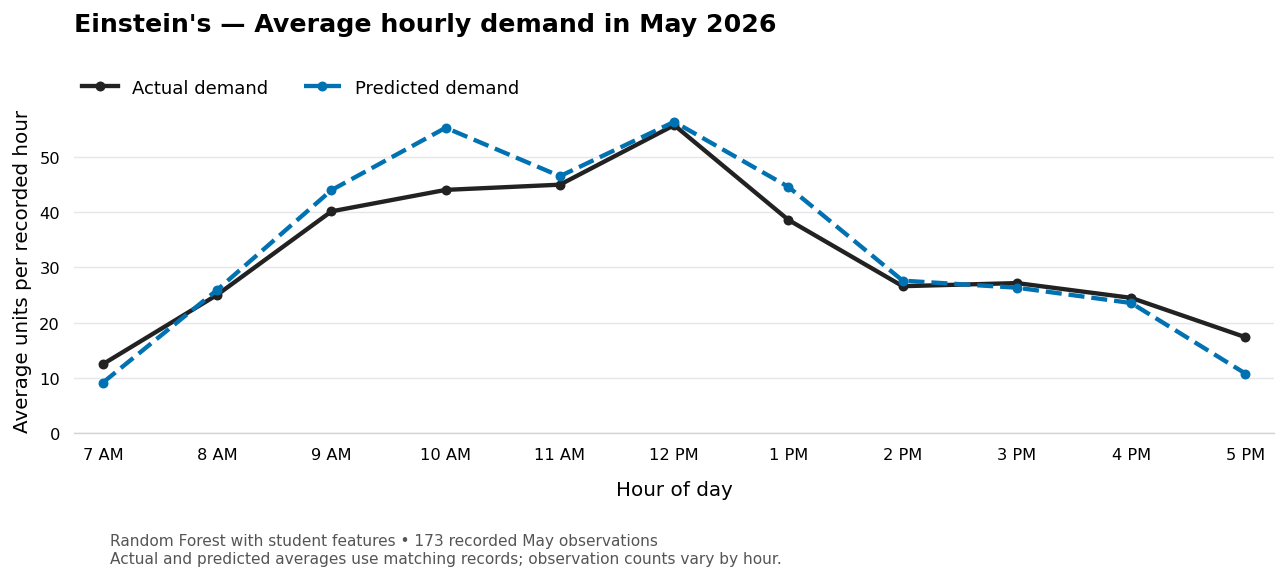

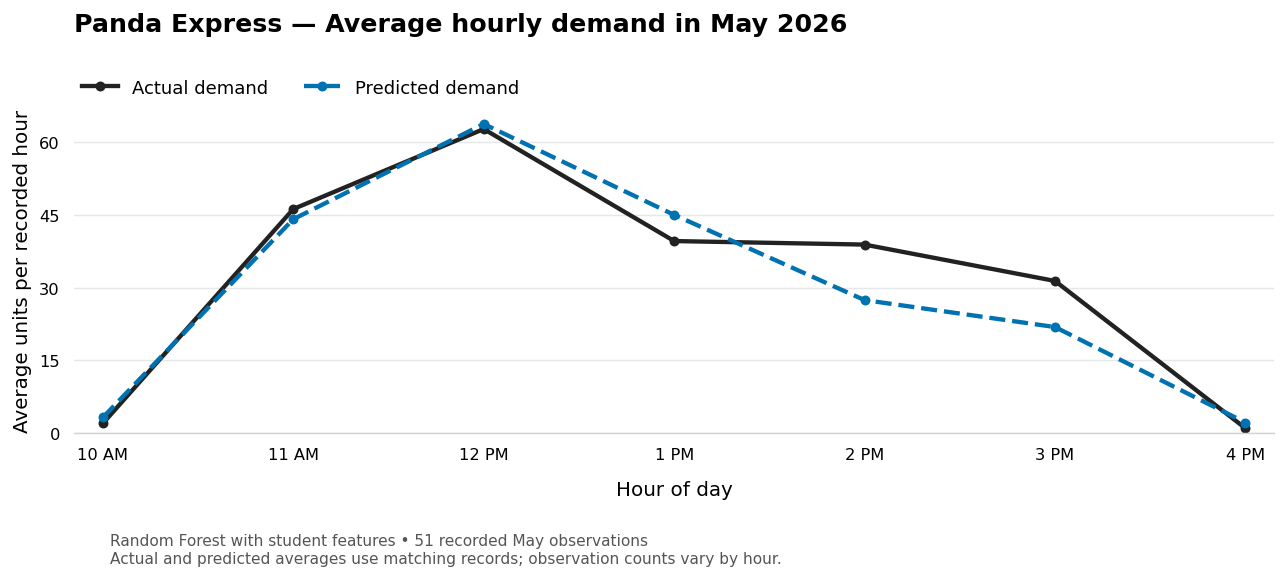

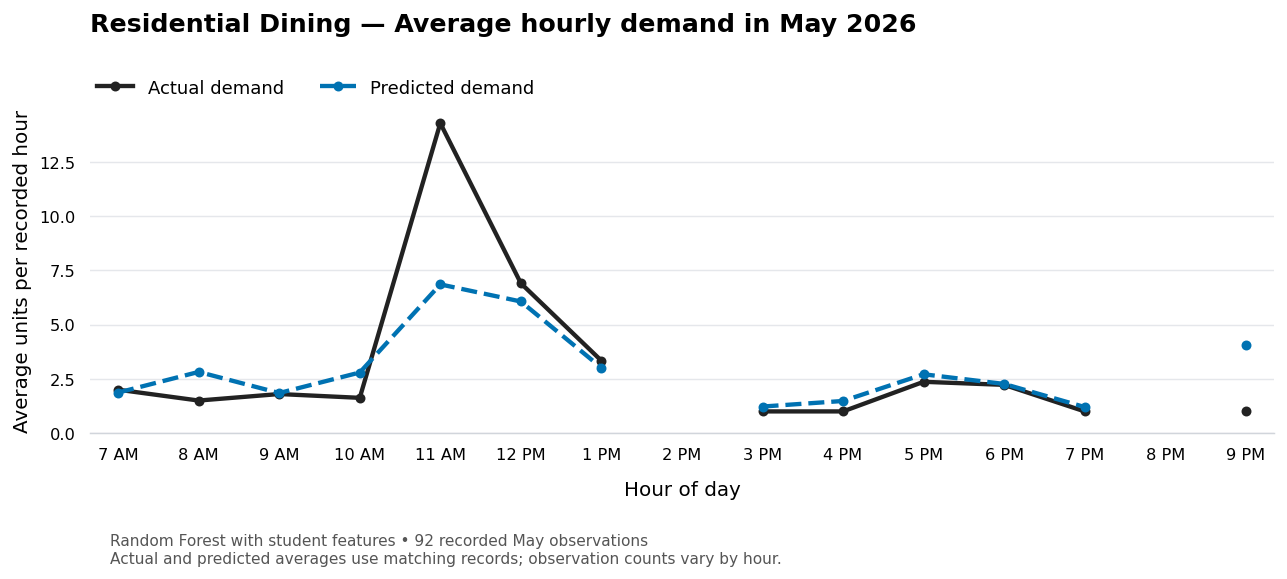

In [33]:
from matplotlib.ticker import FuncFormatter, MaxNLocator

# Retrieve the hourly model selected before evaluating May.
hourly_model_name, hourly_configuration = selected_lookup["Hourly"]

hourly_visualization_data = may_predictions[
    ("Hourly", hourly_configuration, hourly_model_name)
].copy()

# Summarize actual and predicted demand using the same recorded observations.
hourly_profile = (
    hourly_visualization_data
    .groupby(["Location", "Hour"], as_index=False)
    .agg(
        ActualAverage=("Actual", "mean"),
        PredictedAverage=("Predicted", "mean"),
        Observations=("Actual", "size"),
    )
)


def format_hour(value, position=None):
    """Display an integer hour as a readable clock label."""
    hour = int(value)
    suffix = "AM" if hour < 12 else "PM"
    return f"{hour % 12 or 12} {suffix}"


for location in sorted(hourly_profile["Location"].unique()):
    profile = (
        hourly_profile.loc[
            hourly_profile["Location"].eq(location)
        ]
        .set_index("Hour")
        .sort_index()
    )

    observation_count = int(profile["Observations"].sum())

    # Leave completely unrecorded hours as gaps rather than zeros.
    hours = range(
        int(profile.index.min()),
        int(profile.index.max()) + 1,
    )

    plotted = profile.reindex(hours)

    fig, ax = plt.subplots(figsize=(10, 4.5), dpi=130)

    ax.plot(
        plotted.index,
        plotted["ActualAverage"],
        color="#222222",
        linewidth=2.4,
        marker="o",
        markersize=4.5,
        label="Actual demand",
    )

    ax.plot(
        plotted.index,
        plotted["PredictedAverage"],
        color="#0072B2",
        linewidth=2.4,
        linestyle="--",
        marker="o",
        markersize=4.5,
        label="Predicted demand",
    )

    ax.set_title(
        f"{location} — Average hourly demand in May 2026",
        loc="left",
        fontsize=14,
        fontweight="bold",
        pad=43,
    )

    # Keep the legend above the plotting area so it cannot cover observations.
    ax.legend(
        loc="lower left",
        bbox_to_anchor=(0, 1.015),
        ncol=2,
        frameon=False,
        fontsize=10,
        borderaxespad=0,
    )

    ax.set_xlabel("Hour of day", fontsize=11, labelpad=10)
    ax.set_ylabel("Average units per recorded hour", fontsize=11)

    ax.set_xticks(list(hours))
    ax.xaxis.set_major_formatter(FuncFormatter(format_hour))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

    ax.set_ylim(bottom=0)
    ax.margins(x=0.025)
    ax.tick_params(axis="both", labelsize=9, length=0, pad=8)

    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E5E7EB", linewidth=0.8)

    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#D1D5DB")

    fig.text(
        0.09,
        0.025,
        f"Random Forest with student features • "
        f"{observation_count} recorded May observations\n"
        "Actual and predicted averages use matching records; "
        "observation counts vary by hour.",
        fontsize=8.5,
        color="#555555",
    )

    fig.tight_layout(rect=[0, 0.10, 1, 1])
    plt.show()

## 24. Daily Forecasts by Location

Daily recorded quantities are compared with predictions from the
validation-selected XGBoost model with student features.

Each location has a separate graph covering its recorded May dates.
Unrecorded dates remain gaps and are not assigned zero demand.
Vertical scales differ by location to keep local patterns readable.

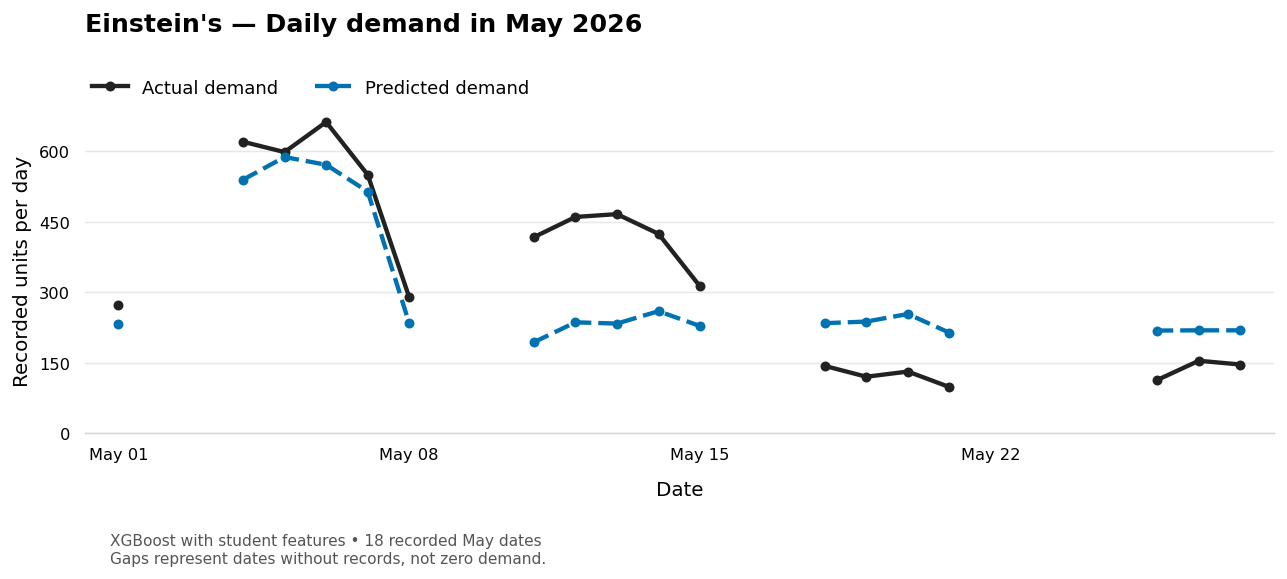

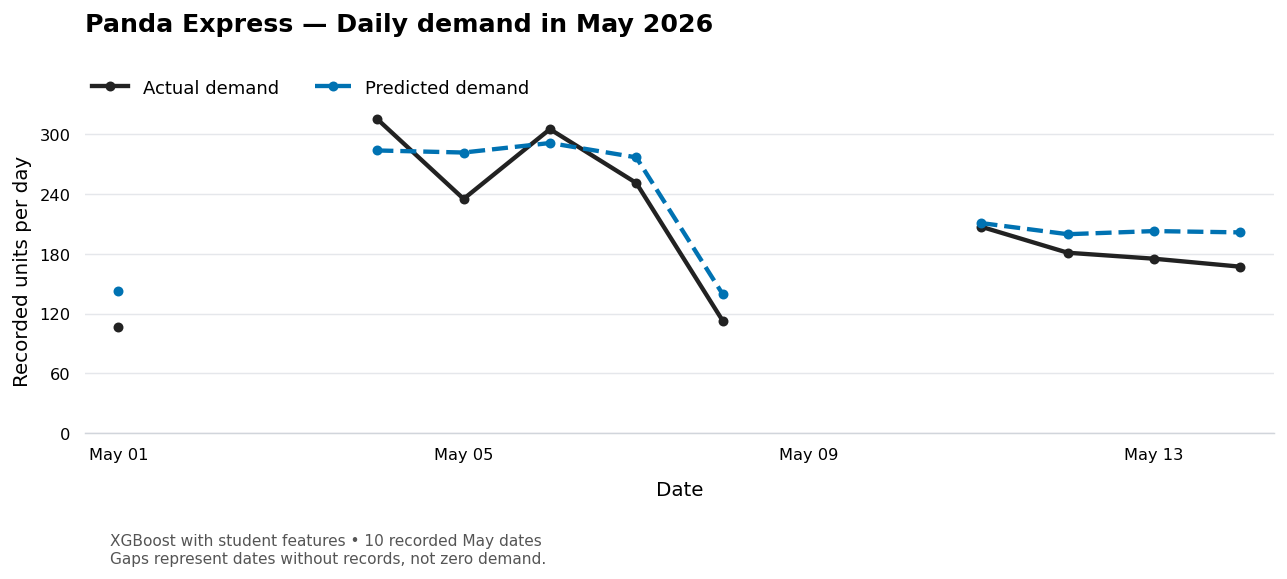

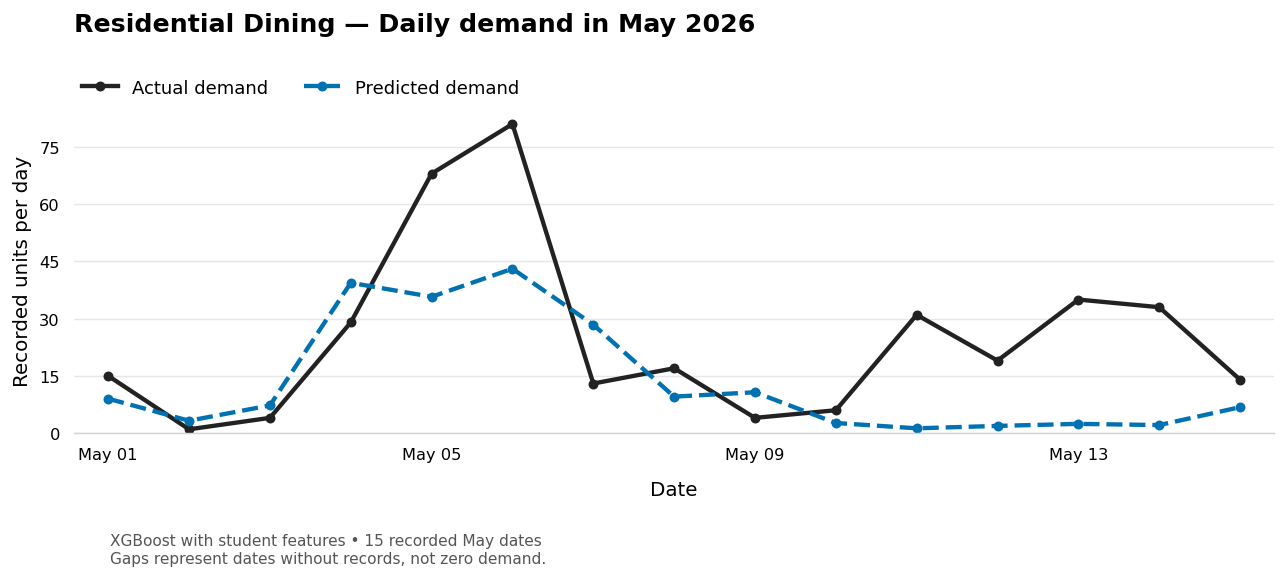

In [34]:
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

# Retrieve the daily model selected during validation.
daily_model_name, daily_configuration = selected_lookup["Daily"]

daily_visualization_data = may_predictions[
    ("Daily", daily_configuration, daily_model_name)
].copy()

for location in sorted(
    daily_visualization_data["Location"].unique()
):
    location_data = (
        daily_visualization_data.loc[
            daily_visualization_data["Location"].eq(location),
            ["Date", "Actual", "Predicted"],
        ]
        .sort_values("Date")
        .set_index("Date")
    )

    # Preserve missing dates as visible gaps without introducing zeros.
    display_dates = pd.date_range(
        location_data.index.min(),
        location_data.index.max(),
        freq="D",
    )

    plotted = location_data.reindex(display_dates)

    fig, ax = plt.subplots(figsize=(10, 4.5), dpi=130)

    ax.plot(
        plotted.index,
        plotted["Actual"],
        color="#222222",
        linewidth=2.4,
        marker="o",
        markersize=4.5,
        label="Actual demand",
    )

    ax.plot(
        plotted.index,
        plotted["Predicted"],
        color="#0072B2",
        linewidth=2.4,
        linestyle="--",
        marker="o",
        markersize=4.5,
        label="Predicted demand",
    )

    ax.set_title(
        f"{location} — Daily demand in May 2026",
        loc="left",
        fontsize=14,
        fontweight="bold",
        pad=43,
    )

    ax.legend(
        loc="lower left",
        bbox_to_anchor=(0, 1.015),
        ncol=2,
        frameon=False,
        fontsize=10,
        borderaxespad=0,
    )

    ax.set_xlabel("Date", fontsize=11, labelpad=10)
    ax.set_ylabel("Recorded units per day", fontsize=11)

    locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))

    ax.set_ylim(bottom=0)
    ax.margins(x=0.03)
    ax.tick_params(axis="both", labelsize=9, length=0, pad=8)

    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E5E7EB", linewidth=0.8)

    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#D1D5DB")

    fig.text(
        0.09,
        0.025,
        f"{daily_model_name} with student features • "
        f"{len(location_data)} recorded May dates\n"
        "Gaps represent dates without records, not zero demand.",
        fontsize=8.5,
        color="#555555",
    )

    fig.tight_layout(rect=[0, 0.10, 1, 1])
    plt.show()

## 25. Forecast Error by Weekday and Hour

MAE is examined by weekday for hourly and daily forecasts, and by hour
of day for hourly forecasts.

These charts use the validation-selected model at each forecasting level
and the common May observations used for baseline comparisons.
Lower bars indicate smaller average absolute errors.

Labels above the bars show observation counts. Groups with fewer
observations provide less evidence about typical performance.
Weekdays and hours without eligible observations are omitted.

Results combine the three locations. Differences can reflect both
forecasting difficulty and the locations represented within each group.
Hourly and daily MAE have different units of aggregation and should
be interpreted separately.

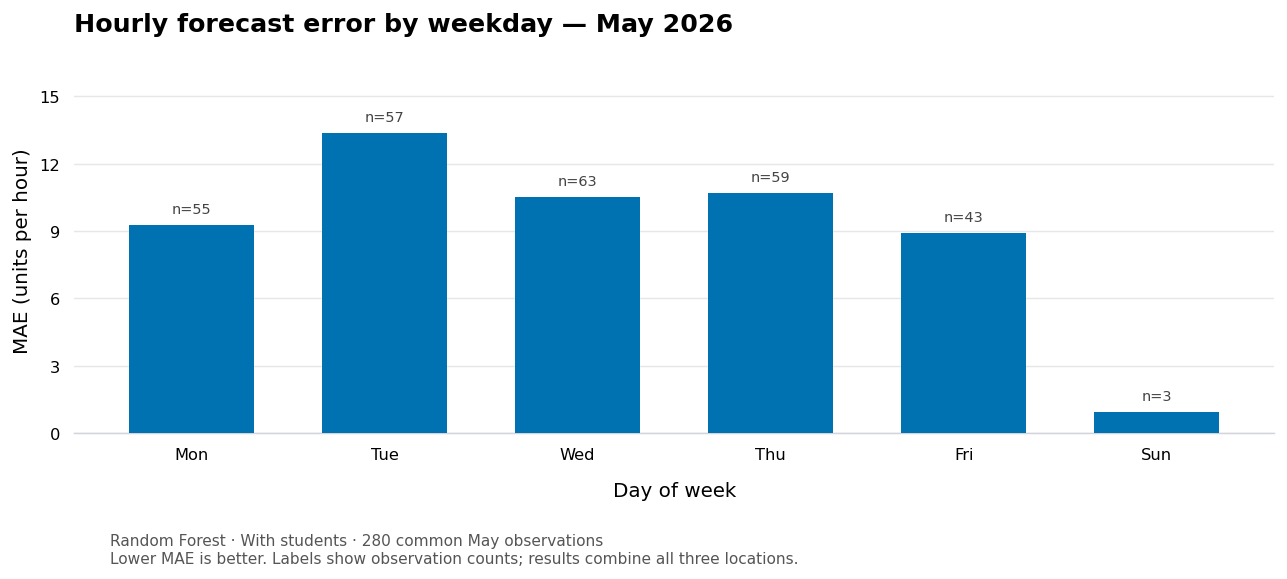

,Weekday,Observations,MAE,RMSE,MAPE (%)
0,Monday,55,9.265,13.044,48.526
1,Tuesday,57,13.363,17.515,92.380
2,Wednesday,63,10.528,14.536,62.121
3,Thursday,59,10.680,13.909,110.107
4,Friday,43,8.912,12.079,65.335
5,Sunday,3,0.937,1.047,44.706


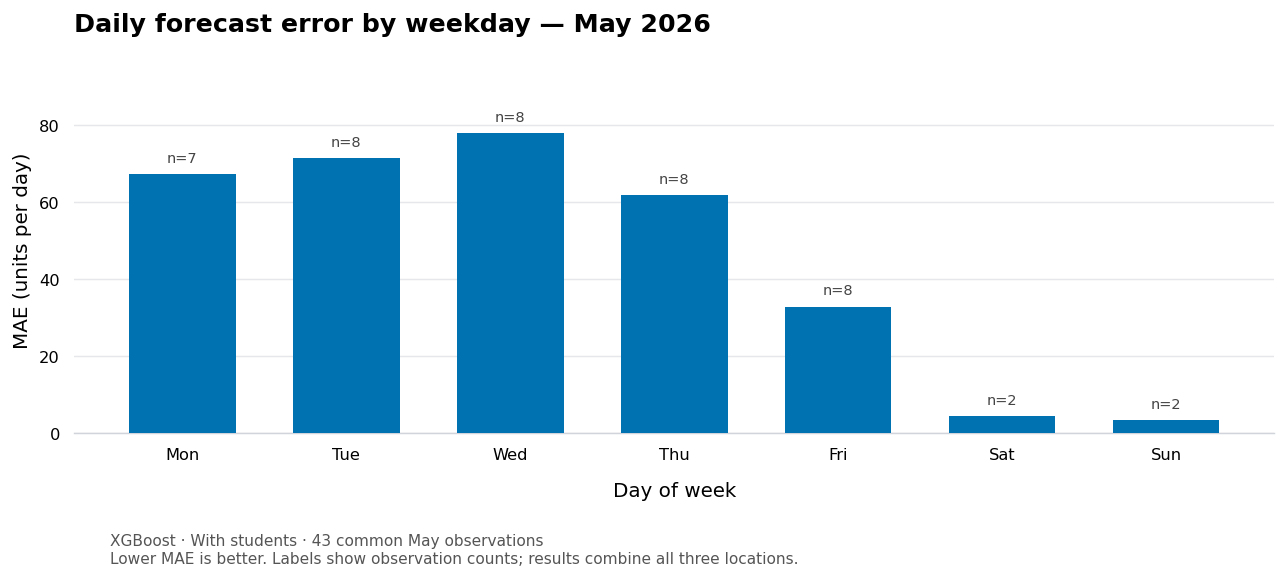

,Weekday,Observations,MAE,RMSE,MAPE (%)
0,Monday,7,67.216,97.649,39.110
1,Tuesday,8,71.484,99.426,51.130
2,Wednesday,8,77.904,103.188,44.947
3,Thursday,8,61.898,79.093,57.013
4,Friday,8,32.888,41.709,31.774
5,Saturday,2,4.477,5.003,196.043
6,Sunday,2,3.303,3.304,68.644


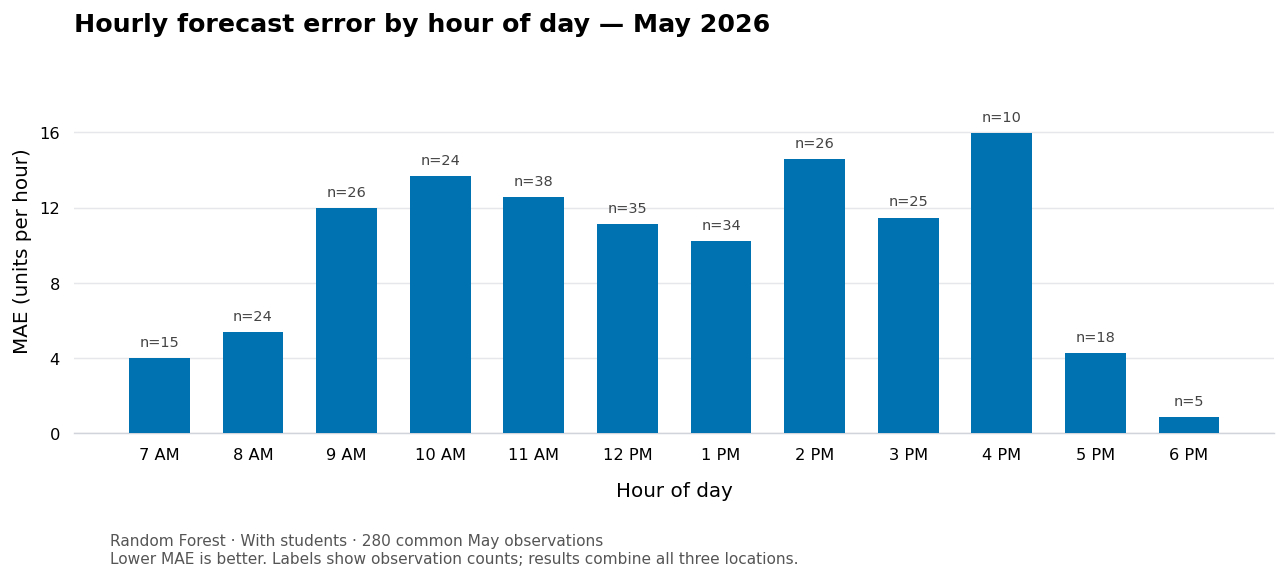

,Hour,Observations,MAE,RMSE,MAPE (%)
0,7,15,4.013,6.213,53.822
1,8,24,5.385,7.219,59.192
2,9,26,11.975,15.943,78.036
3,10,24,13.678,18.645,126.960
4,11,38,12.580,17.319,48.537
5,12,35,11.132,14.170,34.525
6,13,34,10.231,13.648,64.720
7,14,26,14.570,16.213,105.155
8,15,25,11.468,13.848,99.399
9,16,10,15.956,19.295,232.261


In [35]:
from matplotlib.ticker import MaxNLocator

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday",
]


def plot_grouped_mae(level, group_type):
    """Display errors for the validation-selected model on common May rows."""
    results = may_grouped_metrics.loc[
        may_grouped_metrics["ForecastLevel"].eq(level)
        & may_grouped_metrics["GroupType"].eq(group_type)
        & may_grouped_metrics["ValidationSelected"]
    ].copy()

    if results.empty:
        raise ValueError(f"No results found for {level}, {group_type}.")

    if group_type == "Weekday":
        order = {
            day: position
            for position, day in enumerate(weekday_order)
        }
        results["DisplayOrder"] = results["Group"].map(order)
        results = results.sort_values("DisplayOrder")

        labels = [
            str(day)[:3] for day in results["Group"]
        ]
        x_label = "Day of week"
        title = f"{level} forecast error by weekday"

    else:
        results["DisplayOrder"] = pd.to_numeric(results["Group"])
        results = results.sort_values("DisplayOrder")

        labels = [
            format_hour(hour)
            for hour in results["DisplayOrder"]
        ]
        x_label = "Hour of day"
        title = "Hourly forecast error by hour of day"

    model_name, configuration = selected_lookup[level]

    fig, ax = plt.subplots(figsize=(10, 4.5), dpi=130)

    positions = np.arange(len(results))

    bars = ax.bar(
        positions,
        results["MAE"],
        color="#0072B2",
        width=0.65,
        zorder=3,
    )

    # Counts help readers assess how much evidence supports each bar.
    ax.bar_label(
        bars,
        labels=[
            f"n={int(count)}"
            for count in results["Observations"]
        ],
        padding=5,
        fontsize=8,
        color="#444444",
    )

    ax.set_title(
        f"{title} — May 2026",
        loc="left",
        fontsize=14,
        fontweight="bold",
        pad=20,
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(labels)
    ax.set_xlabel(x_label, fontsize=11, labelpad=10)
    ax.set_ylabel(
        "MAE (units per hour)" if level == "Hourly"
        else "MAE (units per day)",
        fontsize=11,
    )

    upper_limit = max(float(results["MAE"].max()) * 1.22, 1)
    ax.set_ylim(0, upper_limit)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.tick_params(axis="both", labelsize=9, length=0, pad=8)

    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E5E7EB", linewidth=0.8)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#D1D5DB")

    fig.text(
        0.09,
        0.025,
        f"{model_name} · {configuration} · "
        f"{int(results['Observations'].sum())} common May observations\n"
        "Lower MAE is better. Labels show observation counts; "
        "results combine all three locations.",
        fontsize=8.5,
        color="#555555",
    )

    fig.tight_layout(rect=[0, 0.10, 1, 1])
    plt.show()

    # Retain exact values alongside the visual summary.
    display(
        results[
            ["Group", "Observations", "MAE", "RMSE", "MAPE (%)"]
        ]
        .rename(columns={"Group": group_type})
        .round(3)
        .reset_index(drop=True)
    )


plot_grouped_mae("Hourly", "Weekday")
plot_grouped_mae("Daily", "Weekday")
plot_grouped_mae("Hourly", "Hour")

## 26. Error Patterns and Largest Forecast Deviations

The selected hourly model has its highest weekday MAE on Tuesday.
The selected daily model has its highest weekday MAE on Wednesday.

Among recorded hours, 4 PM has the highest MAE, based on 10 observations.
Weekend groups contain only two or three observations, providing
insufficient evidence for broad conclusions about weekend performance.

These comparisons combine locations and reflect different demand levels
and observation counts. They do not establish the causes of prediction errors.

The largest individual forecast deviations are examined below using the
validation-selected models and common May evaluation observations.
Positive signed errors indicate overprediction; negative signed errors
indicate underprediction. This analysis describes remaining errors
without changing model settings after benchmark evaluation.

In [36]:
selected_error_tables = []
error_summary_records = []

for level in ["Hourly", "Daily"]:
    model_name, configuration = selected_lookup[level]

    selected_errors = may_error_details.loc[
        may_error_details["ForecastLevel"].eq(level)
        & may_error_details["Model"].eq(model_name)
        & may_error_details["Configuration"].eq(configuration)
        & may_error_details["CommonBaselineEligible"]
    ].copy()

    selected_error_tables.append(selected_errors)

    error_summary_records.append({
        "ForecastLevel": level,
        "Model": model_name,
        "Configuration": configuration,
        "Observations": len(selected_errors),
        "MeanSignedError": selected_errors["SignedError"].mean(),
        "Overpredictions": int(
            selected_errors["SignedError"].gt(0).sum()
        ),
        "Underpredictions": int(
            selected_errors["SignedError"].lt(0).sum()
        ),
        "ExactPredictions": int(
            selected_errors["SignedError"].eq(0).sum()
        ),
    })

    display_columns = ["Location", "Date"]

    if level == "Hourly":
        display_columns.append("Hour")

    display_columns += [
        "Actual",
        "Predicted",
        "SignedError",
        "AbsoluteError",
    ]

    largest_errors = (
        selected_errors
        .sort_values(
            ["AbsoluteError", "Date"],
            ascending=[False, True],
        )
        .head(8)
        .copy()
    )

    if level == "Hourly":
        largest_errors["Hour"] = largest_errors["Hour"].astype(int)

    print(f"\n{level}: eight largest absolute errors")
    display(
        largest_errors[display_columns]
        .round(3)
        .reset_index(drop=True)
    )

selected_may_errors = pd.concat(
    selected_error_tables, ignore_index=True
)

selected_error_summary = pd.DataFrame(error_summary_records)

print("\nOverall prediction bias on common May observations:")
display(selected_error_summary.round(3))


Hourly: eight largest absolute errors


,Location,Date,Hour,Actual,Predicted,SignedError,AbsoluteError
0,Residential Dining,2026-05-05,11,57,7.701,-49.299,49.299
1,Einstein's,2026-05-13,16,63,18.748,-44.252,44.252
2,Residential Dining,2026-05-06,11,52,13.103,-38.897,38.897
3,Einstein's,2026-05-20,10,7,44.670,37.670,37.670
4,Einstein's,2026-05-27,10,6,43.057,37.057,37.057
5,Einstein's,2026-05-15,11,72,35.355,-36.645,36.645
6,Einstein's,2026-05-05,9,40,75.570,35.570,35.570
7,Einstein's,2026-05-12,12,82,48.103,-33.897,33.897



Daily: eight largest absolute errors


,Location,Date,Actual,Predicted,SignedError,AbsoluteError
0,Einstein's,2026-05-13,466,233.083,-232.917,232.917
1,Einstein's,2026-05-12,460,235.790,-224.210,224.210
2,Einstein's,2026-05-11,417,193.499,-223.501,223.501
3,Einstein's,2026-05-14,424,259.471,-164.529,164.529
4,Einstein's,2026-05-20,131,253.529,122.529,122.529
5,Einstein's,2026-05-19,120,237.382,117.382,117.382
6,Einstein's,2026-05-21,98,213.581,115.581,115.581
7,Einstein's,2026-05-26,113,218.259,105.259,105.259



Overall prediction bias on common May observations:


,ForecastLevel,Model,Configuration,Observations,MeanSignedError,Overpredictions,Underpredictions,ExactPredictions
0,Hourly,Random Forest,With students,280,0.420,154,126,0
1,Daily,XGBoost,With students,43,-12.656,20,23,0


## 27. Findings and Conclusions

### Effect of Student Features

Adding scheduled student activity reduced validation MAE in nine of the
ten model comparisons. After refitting on January–April, all five model
families achieved lower May MAE with student features than without them.

These comparisons evaluate separately tuned forecasting configurations;
they do not establish a causal relationship between enrollment and demand.

### Validation-Selected Models

Random Forest with student features was selected for hourly forecasting.
XGBoost with student features was selected for daily forecasting.
Selection used March–April MAE before evaluating May.

On identical May observations:

| Forecast level | Selected model | Observations | MAE | RMSE | MAPE |
|---|---|---:|---:|---:|---:|
| Hourly | Random Forest with students | 280 | 10.538 | 14.373 | 76.029% |
| Daily | XGBoost with students | 43 | 56.732 | 82.835 | 53.071% |

Compared with the previous-week baseline, MAE decreased by approximately
28.6% for hourly forecasts and 20.6% for daily forecasts.

The selected hourly model also produced predictions for all 316 recorded
May hours, with an MAE of 9.555 units. This result uses a different
evaluation sample from the 280-observation baseline comparison.

### Remaining Error Patterns

The selected models achieved lower May MAE than both baselines at each
location. Percentage errors nevertheless remained substantial, particularly
for observations with small actual quantities.

The hourly model underestimated several demand spikes. The daily model's
largest absolute errors occurred at Einstein’s, including underprediction
on May 11–14 and overprediction on several later dates.

Mean signed error was +0.420 units per hour and −12.656 units per day on
the common observations. These averages can conceal offsetting positive
and negative errors and should be interpreted alongside MAE and RMSE.

### Dashboard Use

Hourly predictions support viewing expected demand patterns within a day.
Daily predictions support viewing recorded demand totals by date.
The two models are fitted independently, so their predictions are not
constrained to sum to the same daily total.

The exported May predictions represent a historical benchmark with
daily-updated demand inputs. Forecasting new dates requires updated
historical inputs and the applicable calendar and schedule information.

In [37]:
final_summary_records = []

for level in ["Hourly", "Daily"]:
    model_name, configuration = selected_lookup[level]

    common_results = may_evaluation_results.loc[
        may_evaluation_results["ForecastLevel"].eq(level)
        & may_evaluation_results["Evaluation"].eq(
            "Common baseline comparison"
        )
    ]

    selected_result = common_results.loc[
        common_results["Model"].eq(model_name)
        & common_results["Configuration"].eq(configuration)
    ].iloc[0]

    previous_week_result = common_results.loc[
        common_results["Model"].eq("Previous week")
        & common_results["Configuration"].eq("Baseline")
    ].iloc[0]

    final_summary_records.append({
        "ForecastLevel": level,
        "SelectedModel": model_name,
        "Configuration": configuration,
        "Observations": int(selected_result["Observations"]),
        "MAE": selected_result["MAE"],
        "RMSE": selected_result["RMSE"],
        "MAPE (%)": selected_result["MAPE (%)"],
        "PreviousWeekMAE": previous_week_result["MAE"],
        "MAE reduction vs previous week (%)": (
            100
            * (
                previous_week_result["MAE"]
                - selected_result["MAE"]
            )
            / previous_week_result["MAE"]
        ),
    })

final_model_summary = pd.DataFrame(final_summary_records)

print("Final May comparison on matching observations:")
display(final_model_summary.round(3))

Final May comparison on matching observations:


,ForecastLevel,SelectedModel,Configuration,Observations,MAE,RMSE,MAPE (%),PreviousWeekMAE,MAE reduction vs previous week (%)
0,Hourly,Random Forest,With students,280,10.538,14.373,76.029,14.768,28.641
1,Daily,XGBoost,With students,43,56.732,82.835,53.071,71.465,20.616


## 28. Final Data and Model Handoff

The handoff contains two separate ML flat files:

- Hourly: One row per location, date, and hour.
- Daily: One row per location and date.

Original recorded quantities are preserved. Baseline predictions and
temporary evaluation flags are excluded from the final flat files.
The exact predictor lists are exported separately to distinguish model
inputs from identifiers, targets, and supporting fields.

Separate dashboard files contain the validation-selected models' May
predictions, actual quantities, errors, and baseline predictions.

Saved model packages contain the January–April fitted pipelines and
their required input-column order. Additional files document evaluation
results, selected parameters, and package versions.

The May prediction files represent historical benchmark results, not
forecasts for new dates. Hourly and daily predictions come from
independent models and are not constrained to reconcile.

In [40]:
import json
import zipfile
import tempfile
from pathlib import Path

import joblib
from google.colab import files

# ----------------------------------------------------------
# 1. Prepare the final hourly and daily ML flat files.
# ----------------------------------------------------------

hourly_export_columns = list(source_df.columns)

for column in [
    "ScheduledStudents_DailyPeak",
    "HourlyFitEligible",
]:
    if column not in hourly_export_columns:
        hourly_export_columns.append(column)

final_hourly_flat = (
    hourly_df[hourly_export_columns]
    .sort_values(["Location", "Date", "Hour"])
    .reset_index(drop=True)
)

# Recover stable location identifiers from the finalized source.
if source_df.groupby("Location")["LocationKey"].nunique().ne(1).any():
    raise ValueError("Location identifiers are inconsistent.")

location_keys = (
    source_df[["Location", "LocationKey"]]
    .drop_duplicates()
    .set_index("Location")["LocationKey"]
)

daily_export_source = daily_df.copy()

daily_export_source["LocationKey"] = (
    daily_export_source["Location"].map(location_keys)
)

daily_export_source["DateKey"] = (
    daily_export_source["Date"]
    .dt.strftime("%Y%m%d")
    .astype(int)
)

daily_export_columns = list(dict.fromkeys(
    [
        "LocationKey",
        "Location",
        "DateKey",
        "Date",
        "Target_DailyUnits",
        "DataSplit",
        "ForecastCutoffDate",
        "RecordedHours",
        "NegativeHourlyRecords",
        "DailyFitEligible",
    ]
    + locked_feature_sets["Daily"]["With students"]
))

final_daily_flat = (
    daily_export_source[daily_export_columns]
    .sort_values(["Location", "Date"])
    .reset_index(drop=True)
)

# ----------------------------------------------------------
# 2. Verify original observation identities and quantities.
# ----------------------------------------------------------

source_check = source_df[
    ["Location", "Date", "Hour", "Target_HourlyUnits"]
].copy()

source_check["Date"] = pd.to_datetime(
    source_check["Date"]
).dt.normalize()

source_check["Hour"] = pd.to_numeric(
    source_check["Hour"]
).astype(int)

hourly_check = source_check.merge(
    final_hourly_flat[
        ["Location", "Date", "Hour", "Target_HourlyUnits"]
    ],
    on=["Location", "Date", "Hour"],
    how="outer",
    suffixes=("_source", "_final"),
    indicator=True,
    validate="one_to_one",
)

assert hourly_check["_merge"].eq("both").all(), (
    "Exported hourly observation identities differ from the source."
)

assert np.array_equal(
    hourly_check["Target_HourlyUnits_source"],
    hourly_check["Target_HourlyUnits_final"],
), "Exported hourly quantities differ from the source."

expected_daily = (
    source_check.groupby(["Location", "Date"])
    ["Target_HourlyUnits"]
    .sum()
    .sort_index()
)

exported_daily = (
    final_daily_flat
    .set_index(["Location", "Date"])["Target_DailyUnits"]
    .sort_index()
)

pd.testing.assert_index_equal(
    expected_daily.index,
    exported_daily.index,
)

assert np.array_equal(
    expected_daily.to_numpy(),
    exported_daily.to_numpy(),
), "Exported daily quantities do not reconcile with the source."

assert len(final_hourly_flat) == 2032
assert len(final_daily_flat) == 287
assert final_daily_flat["LocationKey"].notna().all()

# Confirm that timestamps agree with their separate date and hour fields.
expected_hourly_timestamps = (
    pd.to_datetime(final_hourly_flat["Date"]).dt.normalize()
    + pd.to_timedelta(final_hourly_flat["Hour"], unit="h")
)

assert np.array_equal(
    pd.to_datetime(final_hourly_flat["Timestamp"]).to_numpy(),
    expected_hourly_timestamps.to_numpy(),
), "Hourly timestamps do not agree with Date and Hour."

# ----------------------------------------------------------
# 3. Prepare separate hourly and daily dashboard predictions.
# ----------------------------------------------------------

dashboard_exports = {}
feature_records = []
selected_model_metadata = []

for level in ["Hourly", "Daily"]:
    model_name, configuration = selected_lookup[level]
    key = (level, configuration, model_name)

    predictions = may_predictions[key].copy()

    identity_columns = ["Location", "Date"]

    if level == "Hourly":
        identity_columns.append("Hour")
        predictions["Hour"] = predictions["Hour"].astype(int)

    # Attach baseline predictions without replacing unavailable values.
    for baseline_name, output_column in [
        ("Previous week", "PreviousWeekPrediction"),
        ("Historical average", "HistoricalAveragePrediction"),
    ]:
        baseline = (
            may_predictions[(level, "Baseline", baseline_name)]
            [identity_columns + ["Predicted"]]
            .rename(columns={"Predicted": output_column})
        )

        predictions = predictions.merge(
            baseline,
            on=identity_columns,
            how="left",
            validate="one_to_one",
        )

    # Promote predictions before calculating dashboard errors.
    # This preserves their stored values while avoiding float32 arithmetic.
    predictions["Actual"] = predictions["Actual"].astype("float64")
    predictions["Predicted"] = predictions["Predicted"].astype("float64")

    predictions["LocationKey"] = (
        predictions["Location"].map(location_keys)
    )

    predictions["DateKey"] = (
        predictions["Date"]
        .dt.strftime("%Y%m%d")
        .astype(int)
    )

    predictions["ForecastCutoffDate"] = (
        predictions["Date"] - pd.Timedelta(days=1)
    )

    predictions["SignedError"] = (
        predictions["Predicted"] - predictions["Actual"]
    )

    predictions["AbsoluteError"] = (
        predictions["SignedError"].abs()
    )

    predictions["AbsolutePercentageError"] = (
        100
        * predictions["AbsoluteError"]
        / predictions["Actual"].where(
            predictions["Actual"].gt(0)
        )
    )

    predictions["PredictionContext"] = (
        "Historical May 2026 benchmark"
    )

    assert np.isfinite(predictions["Actual"]).all()
    assert np.isfinite(predictions["Predicted"]).all()
    assert predictions["LocationKey"].notna().all()
    assert not predictions.duplicated(identity_columns).any()

    dashboard_exports[level] = (
        predictions
        .sort_values(identity_columns)
        .reset_index(drop=True)
    )

    selected_features = (
        locked_feature_sets[level][configuration]
    )

    for position, feature in enumerate(
        selected_features, start=1
    ):
        feature_records.append({
            "ForecastLevel": level,
            "Model": model_name,
            "Configuration": configuration,
            "InputOrder": position,
            "Feature": feature,
            "Type": (
                "Categorical"
                if feature in ["Location", "Weekday"]
                else "Numeric"
            ),
        })

    selected_model_metadata.append({
        "ForecastLevel": level,
        "Model": model_name,
        "Configuration": configuration,
        "Parameters": locked_parameters[key],
        "InputFeatures": selected_features,
        "LastFittingDate": "2026-04-30",
    })

assert len(dashboard_exports["Hourly"]) == 316
assert len(dashboard_exports["Daily"]) == 43

final_input_list = pd.DataFrame(feature_records)

# Combine validation and May results with explicit period labels.
validation_export = pd.concat(
    [
        all_model_validation.loc[
            all_model_validation["Evaluation"].eq(
                "All validation"
            )
        ],
        common_validation_comparison,
    ],
    ignore_index=True,
)

validation_export["EvaluationPeriod"] = (
    "March-April validation"
)

may_export = may_evaluation_results.copy()
may_export["EvaluationPeriod"] = "May benchmark"

evaluation_export = pd.concat(
    [validation_export, may_export],
    ignore_index=True,
)

# ----------------------------------------------------------
# 4. Document the handoff contents and intended use.
# ----------------------------------------------------------

readme = """ServeSmart Final ML Handoff

FINAL ML FLAT FILES
data/ServeSmart_Final_Hourly_ML.csv
  One row per location-date-hour; 2,032 rows.
  Includes original source fields, daily peak student activity,
  and hourly fitting eligibility.
  Timestamp preserves both the date and hour.

data/ServeSmart_Final_Daily_ML.csv
  One row per location-date; 287 rows.
  Daily targets sum recorded hourly quantities, including adjustments.

MODEL INPUTS
models/Selected_Model_Inputs.csv lists the exact predictor order.
Other flat-file columns must not automatically become model inputs.
RecordedHours describes observed coverage and is not a predictor.

DASHBOARD PREDICTIONS
Separate files contain 316 hourly and 43 daily May predictions.
These are historical benchmark predictions, not forecasts for new dates.
Actual contains recorded quantities.
Predicted contains the validation-selected model's predictions.
Missing baseline predictions remain blank.
CommonBaselineEligible identifies the shared comparison sample.
SignedError = Predicted - Actual.
AbsolutePercentageError is blank when Actual is zero.

SELECTED MODELS
Hourly: Random Forest with student features.
Daily: XGBoost with student features.
Selection used March-April MAE before May benchmark evaluation.
Saved pipelines were fitted on January-April observations.
New-date forecasting requires the corresponding historical inputs
and applicable calendar and schedule information.

DATA HANDLING
Keep hourly and daily demand in separate tables.
Do not sum daily totals repeated across hourly records.
Missing dining hours or dates are not automatically zero demand.
Student counts represent scheduled enrollment, not measured attendance.
Daily peak enrollment is not a count of unique daily students.
Historical demand inputs exclude the forecast date and future dates.
Negative hourly targets are retained but excluded from hourly fitting.
Hourly and daily predictions are independent and need not reconcile.

EXPORT FORMAT
Date fields use YYYY-MM-DD.
Hourly Timestamp uses YYYY-MM-DD HH:MM:SS.
Floating-point values are exported with sufficient precision to
preserve the stored numerical values when read back.

SUPPORTING FILES
Evaluation tables document validation and May performance.
Grouped May metrics cover location, weekday, and hour where applicable.
Model metadata records selected settings and package versions.
Share the completed notebook separately for methods and visualizations.
"""

# ----------------------------------------------------------
# 5. Write and verify the exported CSV files.
# ----------------------------------------------------------

zip_path = Path(
    "/content/ServeSmart_Final_ML_Handoff.zip"
)

export_verification_records = []

with tempfile.TemporaryDirectory(
    prefix="servesmart_handoff_"
) as folder:

    export_root = Path(folder)

    for subfolder in [
        "data", "dashboard", "evaluation", "models"
    ]:
        (export_root / subfolder).mkdir()

    csv_exports = {
        "data/ServeSmart_Final_Hourly_ML.csv":
            final_hourly_flat,
        "data/ServeSmart_Final_Daily_ML.csv":
            final_daily_flat,
        "dashboard/ServeSmart_Hourly_May_Predictions.csv":
            dashboard_exports["Hourly"],
        "dashboard/ServeSmart_Daily_May_Predictions.csv":
            dashboard_exports["Daily"],
        "models/Selected_Model_Inputs.csv":
            final_input_list,
        "evaluation/Final_Model_Summary.csv":
            final_model_summary,
        "evaluation/Model_Evaluation_Results.csv":
            evaluation_export,
        "evaluation/May_Grouped_Metrics.csv":
            may_grouped_metrics,
    }

    for relative_path, table in csv_exports.items():
        export_table = table.copy()
        csv_path = export_root / relative_path

        # Promote floating-point columns before serialization.
        # Casting float32 to float64 preserves the original stored values.
        for column in export_table.select_dtypes(
            include=["floating"]
        ).columns:
            export_table[column] = (
                export_table[column].astype("float64")
            )

        # Format hourly timestamps separately from date-only fields.
        if "Timestamp" in export_table.columns:
            export_table["Timestamp"] = pd.to_datetime(
                export_table["Timestamp"]
            ).dt.strftime("%Y-%m-%d %H:%M:%S")

        export_table.to_csv(
            csv_path,
            index=False,
            date_format="%Y-%m-%d",
            float_format="%.17g",
        )

        # Read back with round-trip floating-point precision.
        reloaded = pd.read_csv(
            csv_path,
            float_precision="round_trip",
        )

        assert len(reloaded) == len(table), (
            f"Exported row count changed: {relative_path}"
        )

        assert reloaded.columns.tolist() == table.columns.tolist(), (
            f"Exported columns changed: {relative_path}"
        )

        if "Timestamp" in export_table.columns:
            expected_timestamps = (
                pd.to_datetime(table["Date"]).dt.normalize()
                + pd.to_timedelta(table["Hour"], unit="h")
            )

            assert np.array_equal(
                pd.to_datetime(
                    reloaded["Timestamp"]
                ).to_numpy(),
                expected_timestamps.to_numpy(),
            ), f"Timestamp export mismatch: {relative_path}"

        # Verify numerical columns, including missing-value positions.
        numeric_columns = table.select_dtypes(
            include=["number"]
        ).columns

        for column in numeric_columns:
            expected_values = pd.to_numeric(
                table[column]
            ).to_numpy(dtype=float)

            reloaded_values = pd.to_numeric(
                reloaded[column]
            ).to_numpy(dtype=float)

            assert np.allclose(
                reloaded_values,
                expected_values,
                rtol=1e-12,
                atol=1e-10,
                equal_nan=True,
            ), (
                f"Exported values changed in "
                f"{relative_path}: {column}"
            )

        export_verification_records.append({
            "File": relative_path,
            "Rows": len(reloaded),
            "Columns": len(reloaded.columns),
            "ReadBackCheck": "Passed",
        })

    # ------------------------------------------------------
    # 6. Save selected fitted models and model metadata.
    # ------------------------------------------------------

    for level in ["Hourly", "Daily"]:
        model_name, configuration = selected_lookup[level]
        key = (level, configuration, model_name)

        joblib.dump(
            {
                "pipeline": final_tabular_models[key],
                "features":
                    locked_feature_sets[level][configuration],
                "forecast_level": level,
                "model": model_name,
                "configuration": configuration,
                "last_fitting_date": "2026-04-30",
            },
            export_root / "models"
            / f"{level}_Selected_Model.joblib",
        )

    metadata = {
        "SelectedModels": selected_model_metadata,
        "PackageVersions":
            package_versions.to_dict(orient="records"),
        "HourlyRows": len(final_hourly_flat),
        "DailyRows": len(final_daily_flat),
        "HourlyMayPredictions":
            len(dashboard_exports["Hourly"]),
        "DailyMayPredictions":
            len(dashboard_exports["Daily"]),
        "TimestampFormat": "%Y-%m-%d %H:%M:%S",
        "DateFormat": "%Y-%m-%d",
        "FloatExportFormat": "%.17g",
        "CSVReadPrecision": "round_trip",
    }

    def json_default(value):
        if isinstance(value, np.generic):
            return value.item()
        raise TypeError(
            f"Unsupported metadata type: {type(value)}"
        )

    (
        export_root / "models" / "Model_Metadata.json"
    ).write_text(
        json.dumps(
            metadata,
            indent=2,
            default=json_default,
        ),
        encoding="utf-8",
    )

    (export_root / "README.txt").write_text(
        readme,
        encoding="utf-8",
    )

    # Create a replacement ZIP from this export's files only.
    with zipfile.ZipFile(
        zip_path,
        "w",
        compression=zipfile.ZIP_DEFLATED,
    ) as archive:
        for path in sorted(export_root.rglob("*")):
            if path.is_file():
                archive.write(
                    path,
                    arcname=str(
                        path.relative_to(export_root)
                    ),
                )

# ----------------------------------------------------------
# 7. Verify the ZIP and download the completed handoff.
# ----------------------------------------------------------

with zipfile.ZipFile(zip_path) as archive:
    damaged_file = archive.testzip()

    if damaged_file is not None:
        raise ValueError(
            f"ZIP integrity check failed: {damaged_file}"
        )

export_summary = pd.DataFrame([
    {
        "File": "Final hourly ML flat file",
        "Rows": len(final_hourly_flat),
        "Columns": final_hourly_flat.shape[1],
    },
    {
        "File": "Final daily ML flat file",
        "Rows": len(final_daily_flat),
        "Columns": final_daily_flat.shape[1],
    },
    {
        "File": "Hourly dashboard predictions",
        "Rows": len(dashboard_exports["Hourly"]),
        "Columns": dashboard_exports["Hourly"].shape[1],
    },
    {
        "File": "Daily dashboard predictions",
        "Rows": len(dashboard_exports["Daily"]),
        "Columns": dashboard_exports["Daily"].shape[1],
    },
])

print("Final export summary:")
display(export_summary)

print("\nCSV read-back verification:")
display(pd.DataFrame(export_verification_records))

print("\nPassed: original recorded quantities are preserved.")
print("Passed: hourly timestamps retain both date and hour.")
print("Passed: numerical values passed CSV read-back checks.")
print("Passed: ZIP integrity check.")
print(f"\nReplacement ZIP ready: {zip_path}")

files.download(str(zip_path))

Final export summary:


,File,Rows,Columns
0,Final hourly ML flat file,2032,73
1,Final daily ML flat file,287,30
2,Hourly dashboard predictions,316,19
3,Daily dashboard predictions,43,18



CSV read-back verification:


,File,Rows,Columns,ReadBackCheck
0,data/ServeSmart_Final_Hourly_ML.csv,2032,73,Passed
1,data/ServeSmart_Final_Daily_ML.csv,287,30,Passed
2,dashboard/ServeSmart_Hourly_May_Predictions.csv,316,19,Passed
3,dashboard/ServeSmart_Daily_May_Predictions.csv,43,18,Passed
4,models/Selected_Model_Inputs.csv,45,6,Passed
5,evaluation/Final_Model_Summary.csv,2,9,Passed
6,evaluation/Model_Evaluation_Results.csv,88,12,Passed
7,evaluation/May_Grouped_Metrics.csv,372,14,Passed



Passed: original recorded quantities are preserved.
Passed: hourly timestamps retain both date and hour.
Passed: numerical values passed CSV read-back checks.
Passed: ZIP integrity check.

Replacement ZIP ready: /content/ServeSmart_Final_ML_Handoff.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>